# Visualization of the object produced by 03_2

Read only: inspects shiao_tum.h5ad (subset_and_qc.ipynb + subsetting_all.sh) without modifying it.

- What the pre-CNV annotation had called the malignant cells
- The CNV call against sequencing depth, on the post-QC cells
- Composition: cells per cohort, treatment, response and label after the subset
- Cell cycle, re-scored on this population
- Normalization: the first rows of the raw and scran log-normalized matrices, and the new size factors
- Feature selection: the 2,000 batch-aware HVGs without MT- genes and their overlap with the 01_5 set
- UMAP of the reduced object, by annotation, batch, treatment, CNV and QC

The post-CNV cell type is constant (malignant), so the panels by label use the pre-CNV CellTypist label (cell_type_01_4): the healthy state each tumor cell resembles most, not a tumor taxonomy.

## Packages and paths

In [25]:
from __future__ import annotations

import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import os
import sys

# Plotting
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import colors
from matplotlib.patches import Patch, Rectangle
import seaborn as sns

sc.set_figure_params(dpi=300, facecolor='white')
sc.settings.verbosity = 3

import importlib
# cell_set lives in the phase's utils/.
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'utils'))
import cell_set as C
# Reload so edits to cell_set.py show up without a kernel restart.
importlib.reload(C)

PHASE_DIR = os.path.dirname(os.getcwd())  # 03_drvi_tumoral_epi/
REPO_ROOT = os.path.dirname(PHASE_DIR)

FIG_DIR = os.environ.get('FIG_DIR', os.path.join(PHASE_DIR, 'figures', '03_2_visualization'))
os.makedirs(FIG_DIR, exist_ok=True)
sc.settings.figdir = FIG_DIR

TABLE_DIR = os.environ.get('TABLE_DIR', os.path.join(PHASE_DIR, 'tables', '03_2_visualization'))
os.makedirs(TABLE_DIR, exist_ok=True)

# Same palette as subset_and_qc.ipynb; the light tint is the second panel of a pair.
QC_COLOR = '#2CA02C'
QC_COLOR_LIGHT = 'lightgreen'
SET_TITLE = 'malignant'
SUFFIX = C.compartment() # 'tum', in every figure name

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

print('FIG_DIR  :', FIG_DIR)
print('TABLE_DIR:', TABLE_DIR)
print('colour   :', QC_COLOR, '| title word:', SET_TITLE, '| file suffix:', SUFFIX)

<module 'cell_set' from '/home/catt/QCB-thesis-final/03_drvi_tumoral_epi/utils/cell_set.py'>

FIG_DIR  : /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/figures/03_2_visualization
TABLE_DIR: /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_2_visualization
colour   : #2CA02C | title word: malignant | file suffix: tum


In [26]:
DATA_DIR = os.environ['DATA_DIR'] # export DATA_DIR=<data root> before starting Jupyter
os.environ['DATA_DIR'] = os.path.abspath(os.path.expanduser(DATA_DIR))

C.banner('03_2 visualization')

INPUT_H5AD = str(C.path('.h5ad'))
print('Input :', INPUT_H5AD, '| exists:', os.path.exists(INPUT_H5AD))

BATCH_KEY = C.BATCH_KEY            # 'cohort'
LABEL_KEY = C.LABEL_KEY            # 'cell_type', post-CNV
PRIOR_KEY = C.PRIOR_LABEL_KEY      # 'cell_type_01_4', pre-CNV
STATUS_KEY = C.STATUS_KEY          # 'cnv_status'

03_2 visualization  |  run drvi_tum_64_nomt
DATA_DIR : /home/catt/QCB-thesis-final/datasets

Input : /home/catt/QCB-thesis-final/datasets/03_tum/shiao_tum.h5ad | exists: True


In [27]:
adata = ad.read_h5ad(INPUT_H5AD)
adata

AnnData object with n_obs × n_vars = 41943 × 25197
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'cell_type', 'celltypist_predicted', 'cnv_status', 'cnv_score', 'cnv_corr', 'cell_type_01_4', 'celltypist_predicted_cnv', 'compartment', 'size_factors', 'S_score', 'G2M_score', 'phase'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable'
    uns: 'cell_type_01_4_colors', 'cohort_colors', 'hvg_panel', 'hvg_panel_added', 'hvg_panel_dropped', 'log1p', 'neighbors', 'pca', 'phase_colors', 'umap'
    obsm: 'X

In [28]:
LABEL_FOR_PLOTS = LABEL_KEY if adata.obs[LABEL_KEY].nunique() > 1 else PRIOR_KEY
LABEL_IS_PRIOR = LABEL_FOR_PLOTS == PRIOR_KEY
LABEL_TITLE = ('pre-CNV CellTypist label' if LABEL_IS_PRIOR else 'post-CNV cell type')
HAS_STATUS = STATUS_KEY in adata.obs and adata.obs[STATUS_KEY].nunique() > 1

print(f'{adata.n_obs:,} cells x {adata.n_vars:,} genes')
print(f'{adata.obs[BATCH_KEY].nunique()} cohorts')
print(f'{LABEL_KEY} (post-CNV): {adata.obs[LABEL_KEY].nunique()} level(s) '
      f'-> {sorted(adata.obs[LABEL_KEY].unique())[:4]}')
print(f'{PRIOR_KEY} (pre-CNV) : {adata.obs[PRIOR_KEY].nunique()} level(s)')
print(f'panels are coloured by {LABEL_FOR_PLOTS!r} ({LABEL_TITLE})')
print(f'cnv_status has both classes: {HAS_STATUS}')
print(f'HVGs: {int(adata.var["highly_variable"].sum()):,}')

41,943 cells x 25,197 genes
20 cohorts
cell_type (post-CNV): 1 level(s) -> ['malignant']
cell_type_01_4 (pre-CNV) : 10 level(s)
panels are coloured by 'cell_type_01_4' (pre-CNV CellTypist label)
cnv_status has both classes: False
HVGs: 2,000


## The CNV call

cnv_score and cnv_corr from 03_1, and the call taken off them in call_malignant.ipynb.

<BarContainer object of 10 artists>

Text(4, 0, '22,212')

Text(4, 0, '13,327')

Text(4, 0, '4,564')

Text(4, 0, '1,197')

...

Text(4, 0, '3')

Text(4, 0, '2')

[Text(0, 0, 'Lumsec-prol'),
 Text(0, 1, 'Lumsec-basal'),
 Text(0, 2, 'LummHR-SCGB'),
 Text(0, 3, 'Lumsec-KIT'),
 Text(0, 4, 'LummHR-major'),
 Text(0, 5, 'basal'),
 Text(0, 6, 'Lumsec-major'),
 Text(0, 7, 'LummHR-active'),
 Text(0, 8, 'Lumsec-myo'),
 Text(0, 9, 'Lumsec-HLA')]

Text(0.5, 0, 'cells')

Text(0.5, 1.0, 'What the pre-CNV annotation had called these cells (malignant)')

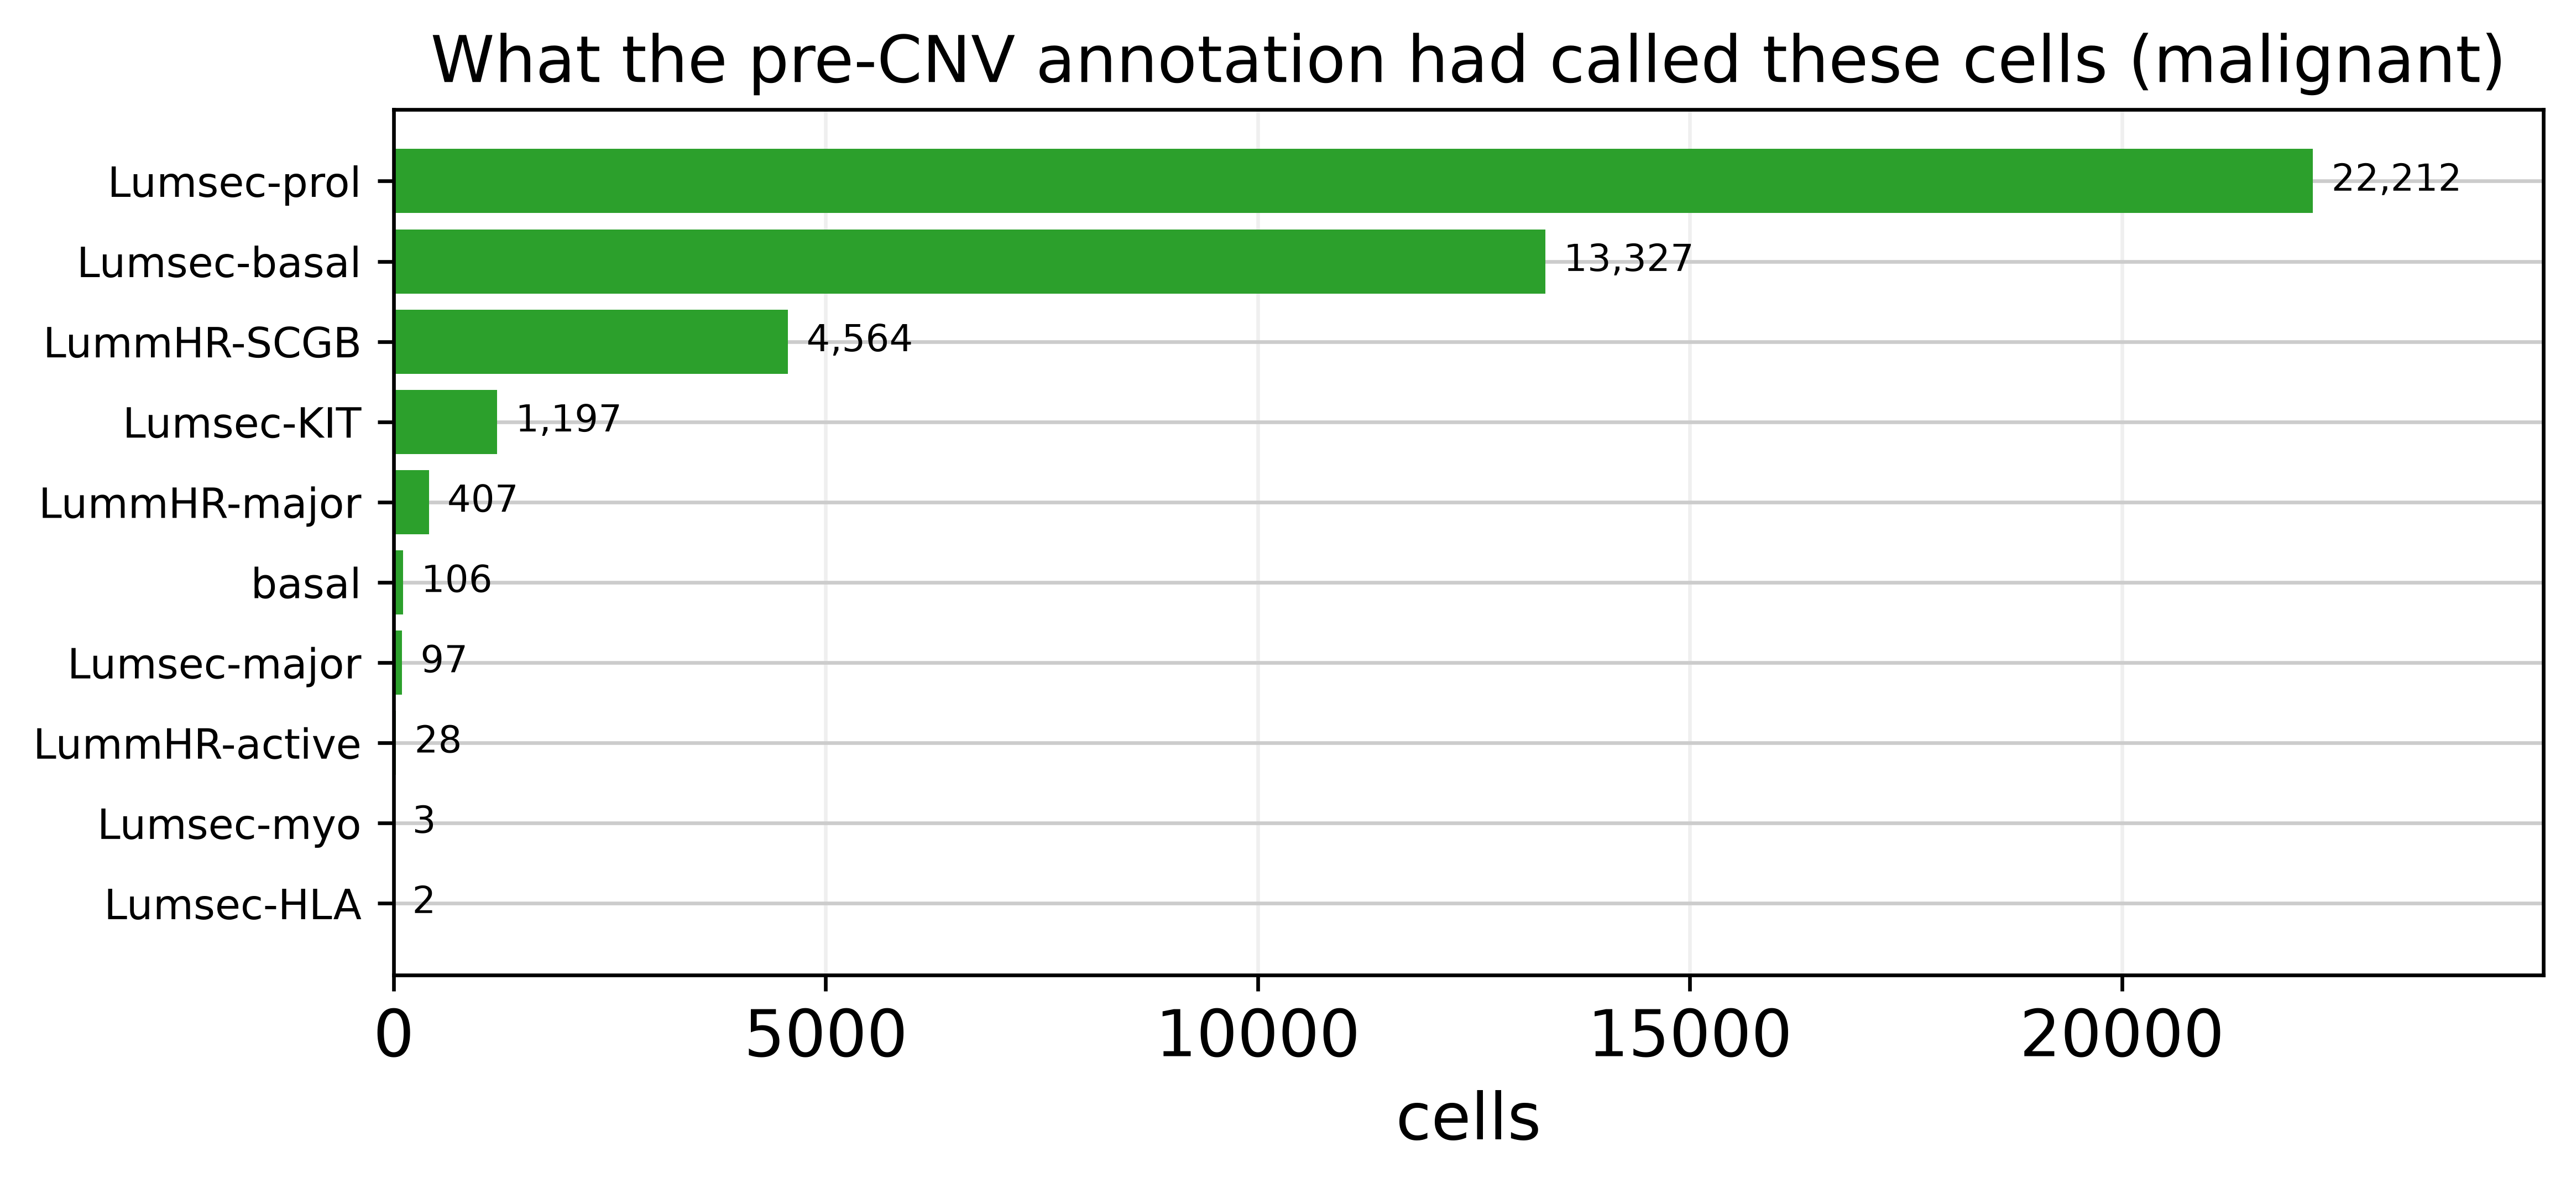

,cells
cell_type_01_4,
Lumsec-prol,22212
Lumsec-basal,13327
LummHR-SCGB,4564
Lumsec-KIT,1197
LummHR-major,407
basal,106
Lumsec-major,97
LummHR-active,28
Lumsec-myo,3


In [29]:
# CellTypist has no malignant class: where it had put the aneuploid cells.
group_cols = [PRIOR_KEY, STATUS_KEY] if HAS_STATUS else [PRIOR_KEY]
comp = adata.obs.groupby(group_cols, observed=True).size()
comp = comp.unstack(fill_value=0) if HAS_STATUS else comp.to_frame('cells')
comp = comp.loc[comp.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, max(3, 0.38 * len(comp))))
left = np.zeros(len(comp))
palette = {'malignant': QC_COLOR, 'non_malignant': '#9AA5B1', 'cells': QC_COLOR}
for col in comp.columns:
    ax.barh(range(len(comp)), comp[col], left=left, color=palette.get(col, '#cccccc'), label=str(col))
    left += comp[col].to_numpy()
for yi, tot in enumerate(comp.sum(axis=1)):
    ax.annotate(f'{tot:,}', (tot, yi), va='center', ha='left', fontsize=8,
                xytext=(4, 0), textcoords='offset points')
ax.set_yticks(range(len(comp)))
ax.set_yticklabels(comp.index, fontsize=9)
ax.invert_yaxis()
ax.margins(x=0.12)
ax.set_xlabel('cells')
ax.set_title(f'What the pre-CNV annotation had called these cells ({SET_TITLE})')
if comp.shape[1] > 1:
    ax.legend(frameon=False, fontsize=8)
ax.grid(axis='x', linestyle='-', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f'barplot_composition_by_prior_label_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()
comp

### CNV vs sequencing depth

1. The call is not driven by depth: across all 196,606 cells scored in 03_1, the correlation with log10 total counts is -0.10 (cnv_score) and +0.07 (cnv_corr).
2. Within the malignant cells, cnv_corr does track depth (+0.53; +0.13 for cnv_score): a shallow cell has a noisier profile, so its correlation with any reference is lower.

So the two scores stay on the object as the record of the call, not as covariates in 03_6.

Text(0.5, 0, 'total_counts')

Text(0, 0.5, 'cnv_score')

Text(0.5, 1.0, 'cnv_score vs library size   (r = +0.128 on log10 counts)')

Text(0.5, 0, 'total_counts')

Text(0, 0.5, 'cnv_corr')

Text(0.5, 1.0, 'cnv_corr vs library size   (r = +0.531 on log10 counts)')

Text(0.5, 1.02, 'Within this subset only (malignant) - the text above gives the values on all tested cells')

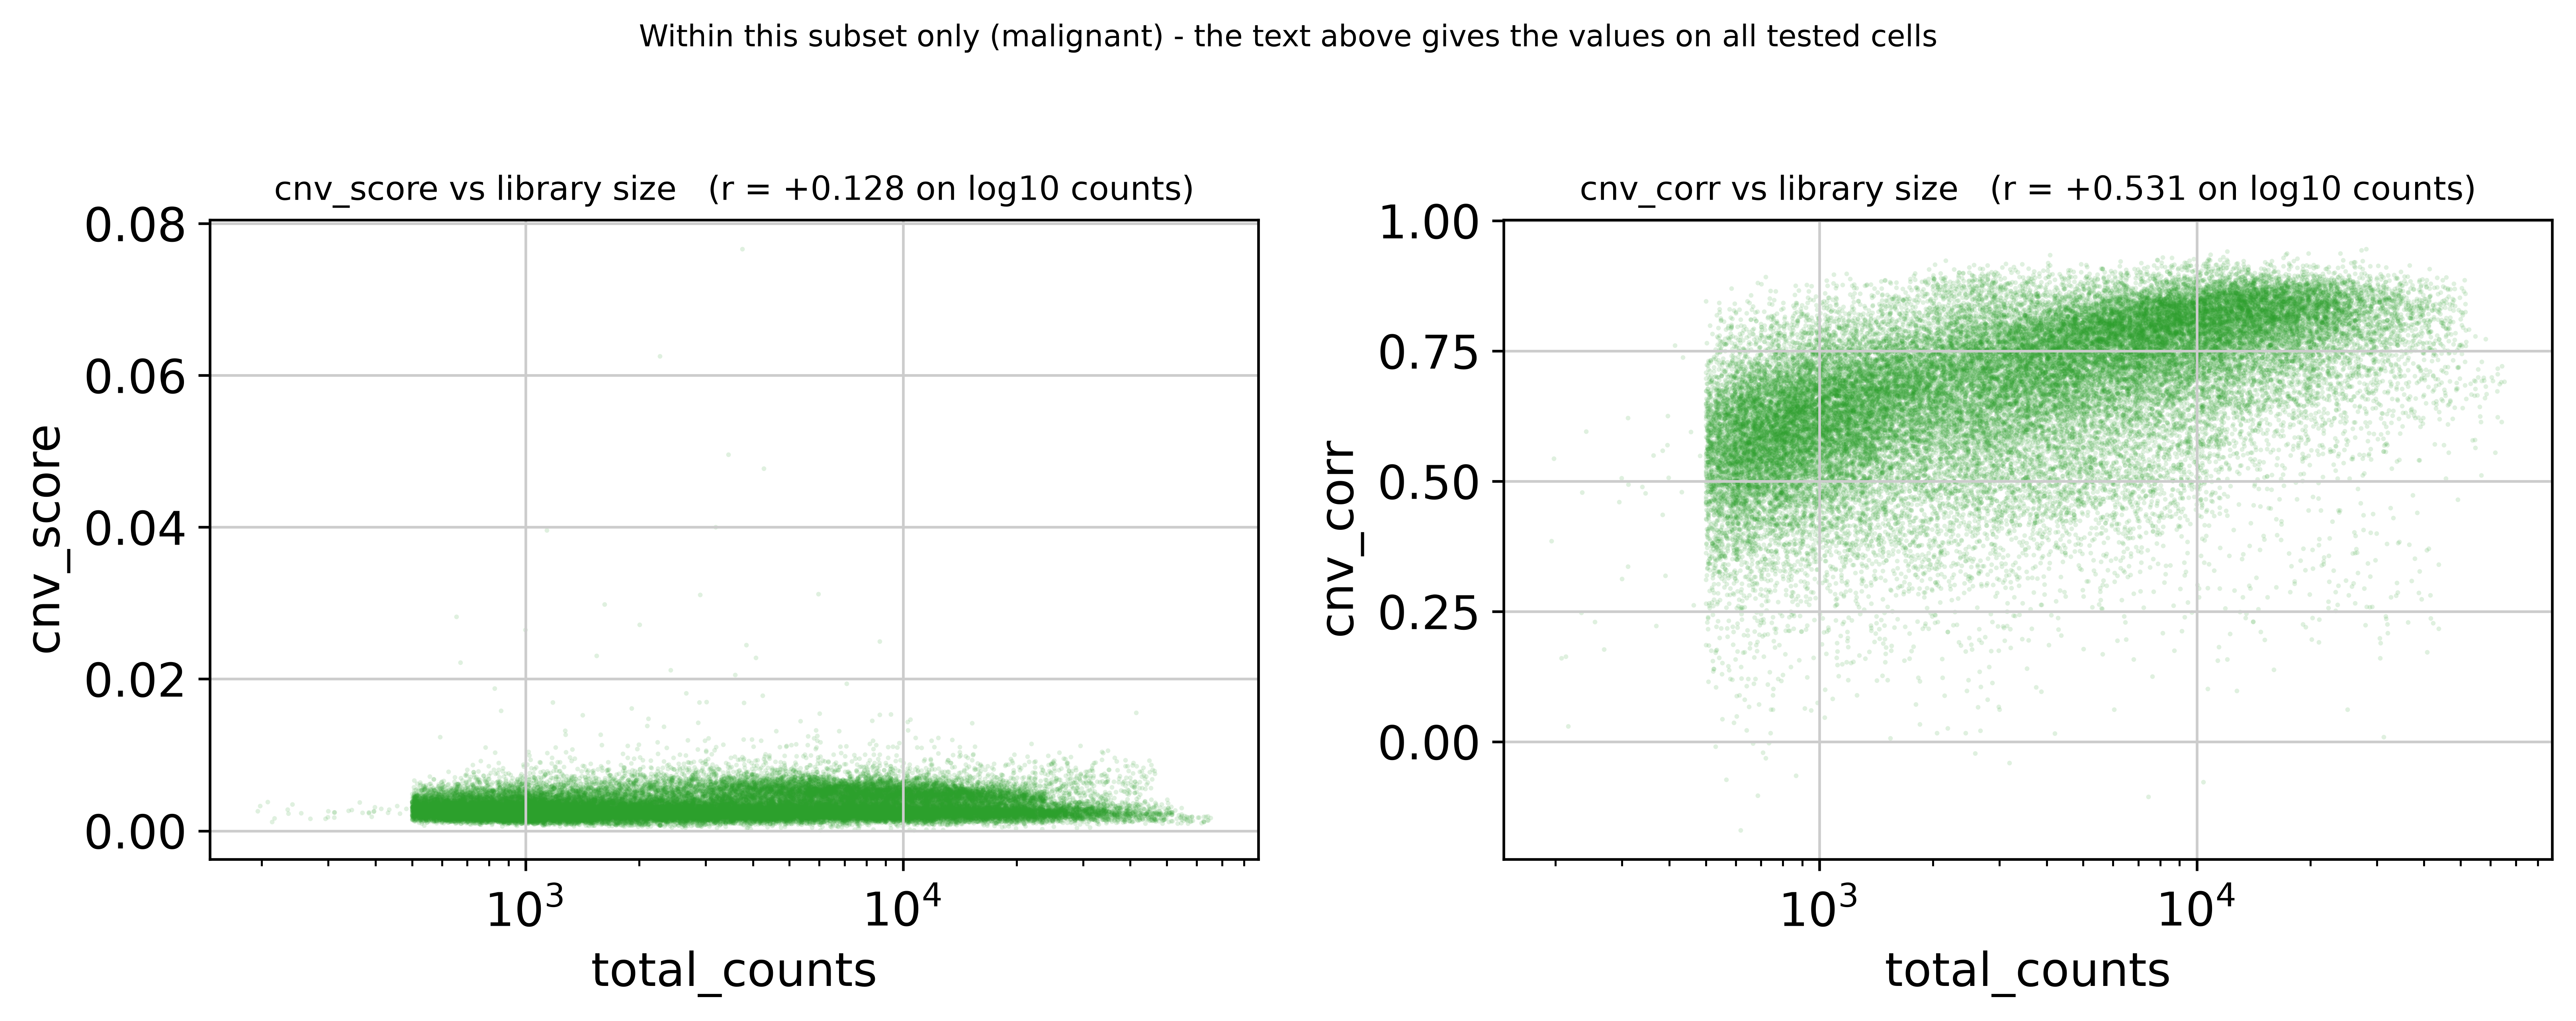

within this subset  : r(cnv_score) = +0.128 | r(cnv_corr) = +0.531


In [30]:
# Within-subset correlation of the two CNV axes with library size.
log_counts = np.log10(adata.obs['total_counts'])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col in zip(axes, ['cnv_score', 'cnv_corr']):
    ax.scatter(adata.obs['total_counts'], adata.obs[col], s=2, alpha=0.15, linewidths=0,
               color=QC_COLOR, rasterized=True)
    ax.set_xscale('log')
    ax.set_xlabel('total_counts'); ax.set_ylabel(col)
    r = np.corrcoef(log_counts, adata.obs[col])[0, 1]
    ax.set_title(f'{col} vs library size   (r = {r:+.3f} on log10 counts)', fontsize=10)
fig.suptitle(f'Within this subset only ({SET_TITLE}) - the text above gives the values on all tested cells',
             y=1.02, fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f'scatter_cnv_vs_depth_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()

print('within this subset  : ' + ' | '.join(
    f"r({c}) = {np.corrcoef(log_counts, adata.obs[c])[0, 1]:+.3f}" for c in ('cnv_score', 'cnv_corr')))

In [31]:
cells_per_cohort = adata.obs[BATCH_KEY].value_counts()
cells_per_cohort = cells_per_cohort[cells_per_cohort > 0].sort_values(ascending=False)


def cohort_order_for_plots(present):
    """Category order, as in 01_6, so a patient sits at the same x position in both phases."""
    present = list(present)
    if adata.obs[BATCH_KEY].dtype.name == 'category':
        return [c for c in adata.obs[BATCH_KEY].cat.categories if c in set(present)]
    return sorted(present)

## Barplots

### Cell counts (cohort, label, treatment, response)

Text(0.5, 1.0, 'Number of malignant cells per cohort')

Text(0.5, 0, 'Cohort')

Text(0, 0.5, 'Number of Cells')

[Text(0, 0, 'Patient01'),
 Text(1, 0, 'Patient09'),
 Text(2, 0, 'Patient10'),
 Text(3, 0, 'Patient11'),
 Text(4, 0, 'Patient16'),
 Text(5, 0, 'Patient17'),
 Text(6, 0, 'Patient18'),
 Text(7, 0, 'Patient19'),
 Text(8, 0, 'Patient20'),
 Text(9, 0, 'Patient26'),
 Text(10, 0, 'Patient42'),
 Text(11, 0, 'Patient43'),
 Text(12, 0, 'Patient45'),
 Text(13, 0, 'Patient46'),
 Text(14, 0, 'Patient47'),
 Text(15, 0, 'Patient48'),
 Text(16, 0, 'Patient53'),
 Text(17, 0, 'Patient56'),
 Text(18, 0, 'Patient63'),
 Text(19, 0, 'Patient64')]

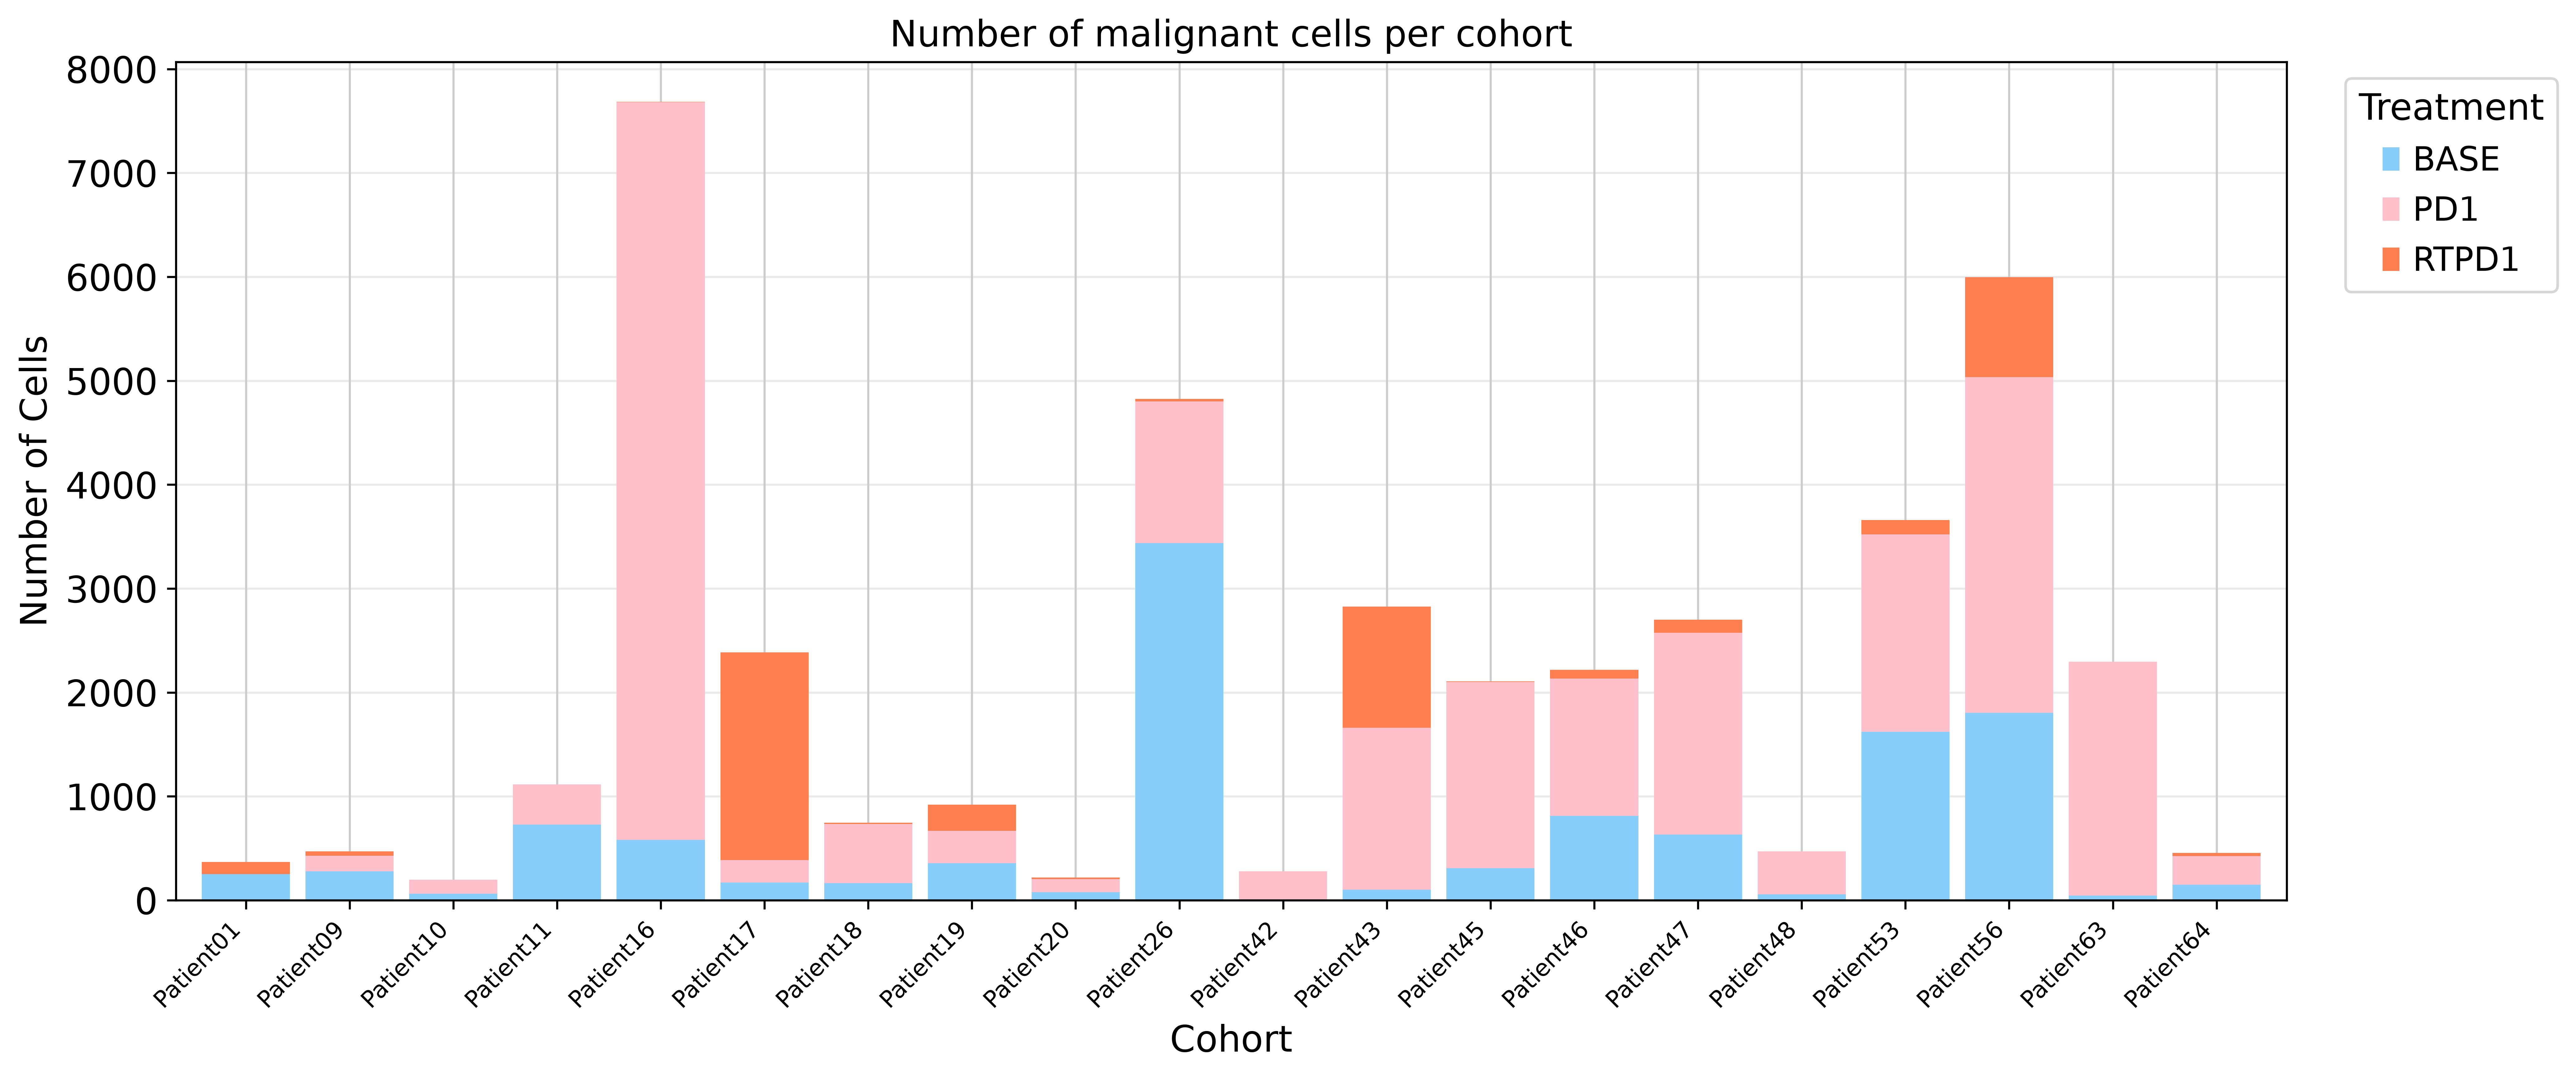

In [32]:
# Cells per cohort, stacked by treatment.
TREATMENT_COLORS = {'BASE': 'lightskyblue', 'PD1': 'pink', 'RTPD1': 'coral'}
treatment_order = [t for t in TREATMENT_COLORS if t in set(adata.obs['treatment'])]

cohort_treatment = pd.crosstab(adata.obs[BATCH_KEY], adata.obs['treatment'])[treatment_order]
cohort_treatment = cohort_treatment.loc[cohort_treatment.sum(axis=1) > 0]
cohort_treatment = cohort_treatment.reindex(cohort_order_for_plots(cohort_treatment.index))

ax = cohort_treatment.plot(kind='bar', stacked=True, figsize=(14, 6), width=0.85,
                           color=[TREATMENT_COLORS[t] for t in treatment_order])
ax.set_title(f'Number of {SET_TITLE} cells per cohort')
ax.set_xlabel('Cohort')
ax.set_ylabel('Number of Cells')
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.set_xticklabels(ax.get_xticklabels(), ha='right')
ax.legend(title='Treatment', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='-', alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'histogram_cells_per_cohort_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()

<Axes: xlabel='cohort'>

Text(0.5, 1.0, 'Number of malignant cells per cohort')

Text(0.5, 0, 'Cohort')

Text(0, 0.5, 'Number of Cells')

[Text(0, 0, 'Patient01'),
 Text(1, 0, 'Patient09'),
 Text(2, 0, 'Patient10'),
 Text(3, 0, 'Patient11'),
 Text(4, 0, 'Patient16'),
 Text(5, 0, 'Patient17'),
 Text(6, 0, 'Patient18'),
 Text(7, 0, 'Patient19'),
 Text(8, 0, 'Patient20'),
 Text(9, 0, 'Patient26'),
 Text(10, 0, 'Patient42'),
 Text(11, 0, 'Patient43'),
 Text(12, 0, 'Patient45'),
 Text(13, 0, 'Patient46'),
 Text(14, 0, 'Patient47'),
 Text(15, 0, 'Patient48'),
 Text(16, 0, 'Patient53'),
 Text(17, 0, 'Patient56'),
 Text(18, 0, 'Patient63'),
 Text(19, 0, 'Patient64')]

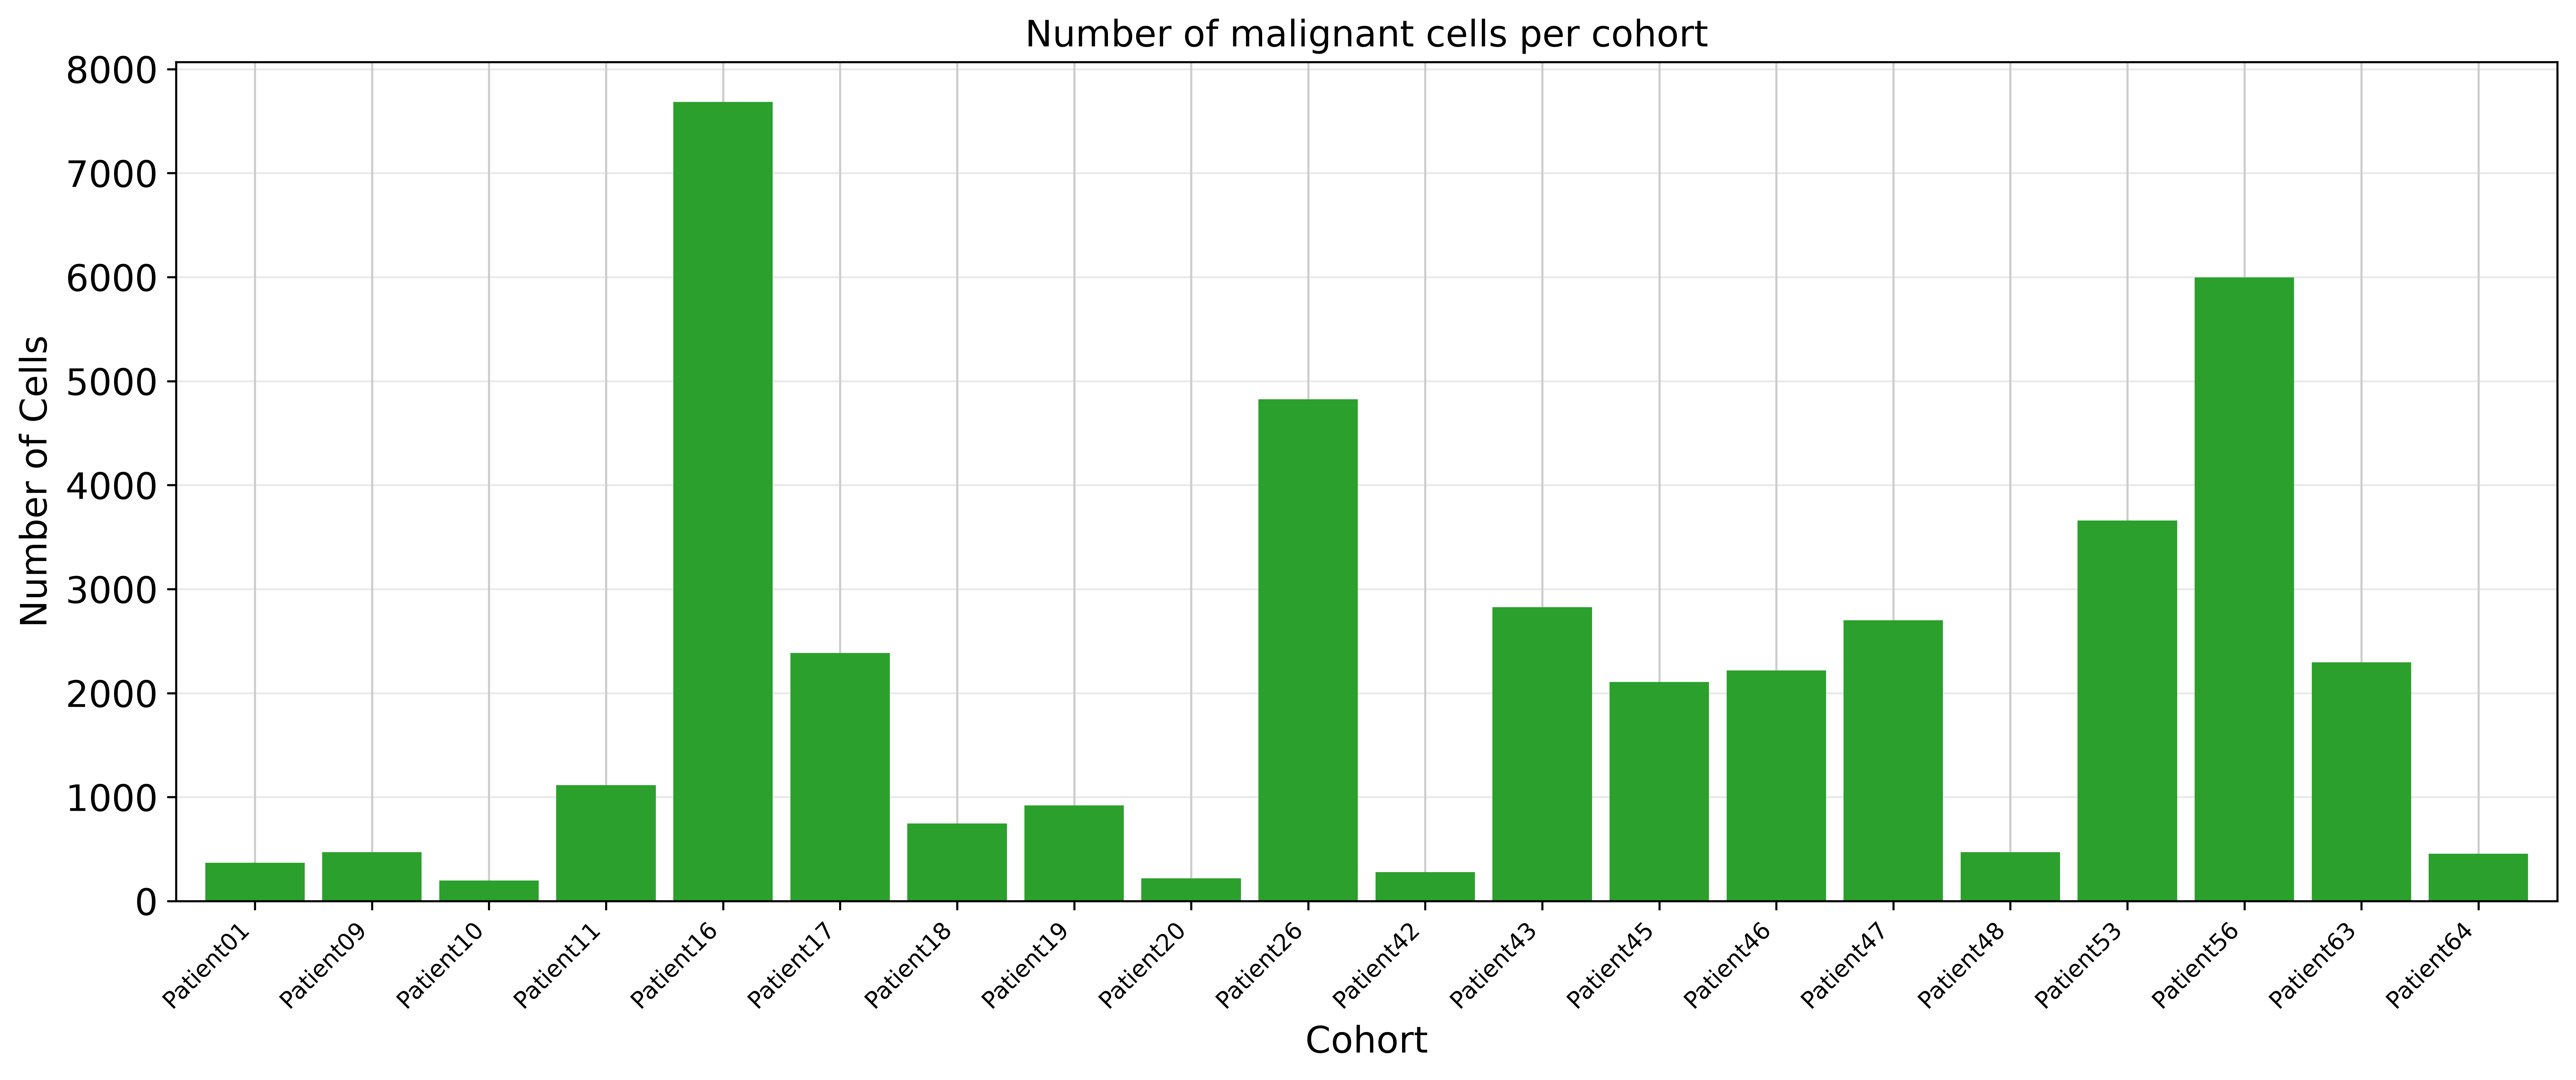

cohort
Patient01     369
Patient09     471
Patient10     199
Patient11    1116
Patient16    7684
Patient17    2386
Patient18     746
Patient19     919
Patient20     218
Patient26    4826
Patient42     278
Patient43    2826
Patient45    2106
Patient46    2218
Patient47    2701
Patient48     472
Patient53    3659
Patient56    5997
Patient63    2297
Patient64     455
Name: count, dtype: int64

In [33]:
# Same counts without the treatment split
cells_per_cohort_ordered = cells_per_cohort.reindex(cohort_order_for_plots(cells_per_cohort.index))

fig, ax = plt.subplots(figsize=(14, 6))
cells_per_cohort_ordered.plot(kind='bar', width=0.85, color=QC_COLOR, ax=ax, legend=False)
ax.set_title(f'Number of {SET_TITLE} cells per cohort')
ax.set_xlabel('Cohort')
ax.set_ylabel('Number of Cells')
ax.tick_params(axis='x', rotation=45, labelsize=9)
ax.set_xticklabels(ax.get_xticklabels(), ha='right')
ax.grid(axis='y', linestyle='-', alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'histogram_cells_per_cohort_single_axis_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()

cells_per_cohort_ordered


In [34]:
# One palette per label, shared by every composition panel below.
label_order = adata.obs[LABEL_FOR_PLOTS].value_counts()
label_order = label_order[label_order > 0].index

_tab20 = list(plt.get_cmap('tab20').colors) + list(plt.get_cmap('tab20b').colors)
_others = [c for c in label_order if c != C.MALIGNANT_LABEL]
LABEL_COLORS = {ct: _tab20[i % len(_tab20)] for i, ct in enumerate(_others)}
if C.MALIGNANT_LABEL in set(label_order):
    LABEL_COLORS[C.MALIGNANT_LABEL] = QC_COLOR


<Axes: xlabel='cohort'>

Text(0, 2, '7,684')

Text(0, 2, '5,997')

Text(0, 2, '4,826')

Text(0, 2, '3,659')

...

Text(0.5, 0, '')

Text(0, 0.5, 'Number of Cells')

[Text(0, 0, 'Patient11'),
 Text(1, 0, 'Patient19'),
 Text(2, 0, 'Patient18'),
 Text(3, 0, 'Patient48'),
 Text(4, 0, 'Patient09'),
 Text(5, 0, 'Patient64'),
 Text(6, 0, 'Patient01'),
 Text(7, 0, 'Patient42'),
 Text(8, 0, 'Patient20'),
 Text(9, 0, 'Patient10')]

Text(0.5, 1.0, 'Cells per cohort and pre-CNV CellTypist label (malignant)')

Text(0.5, 0, 'Cohort')

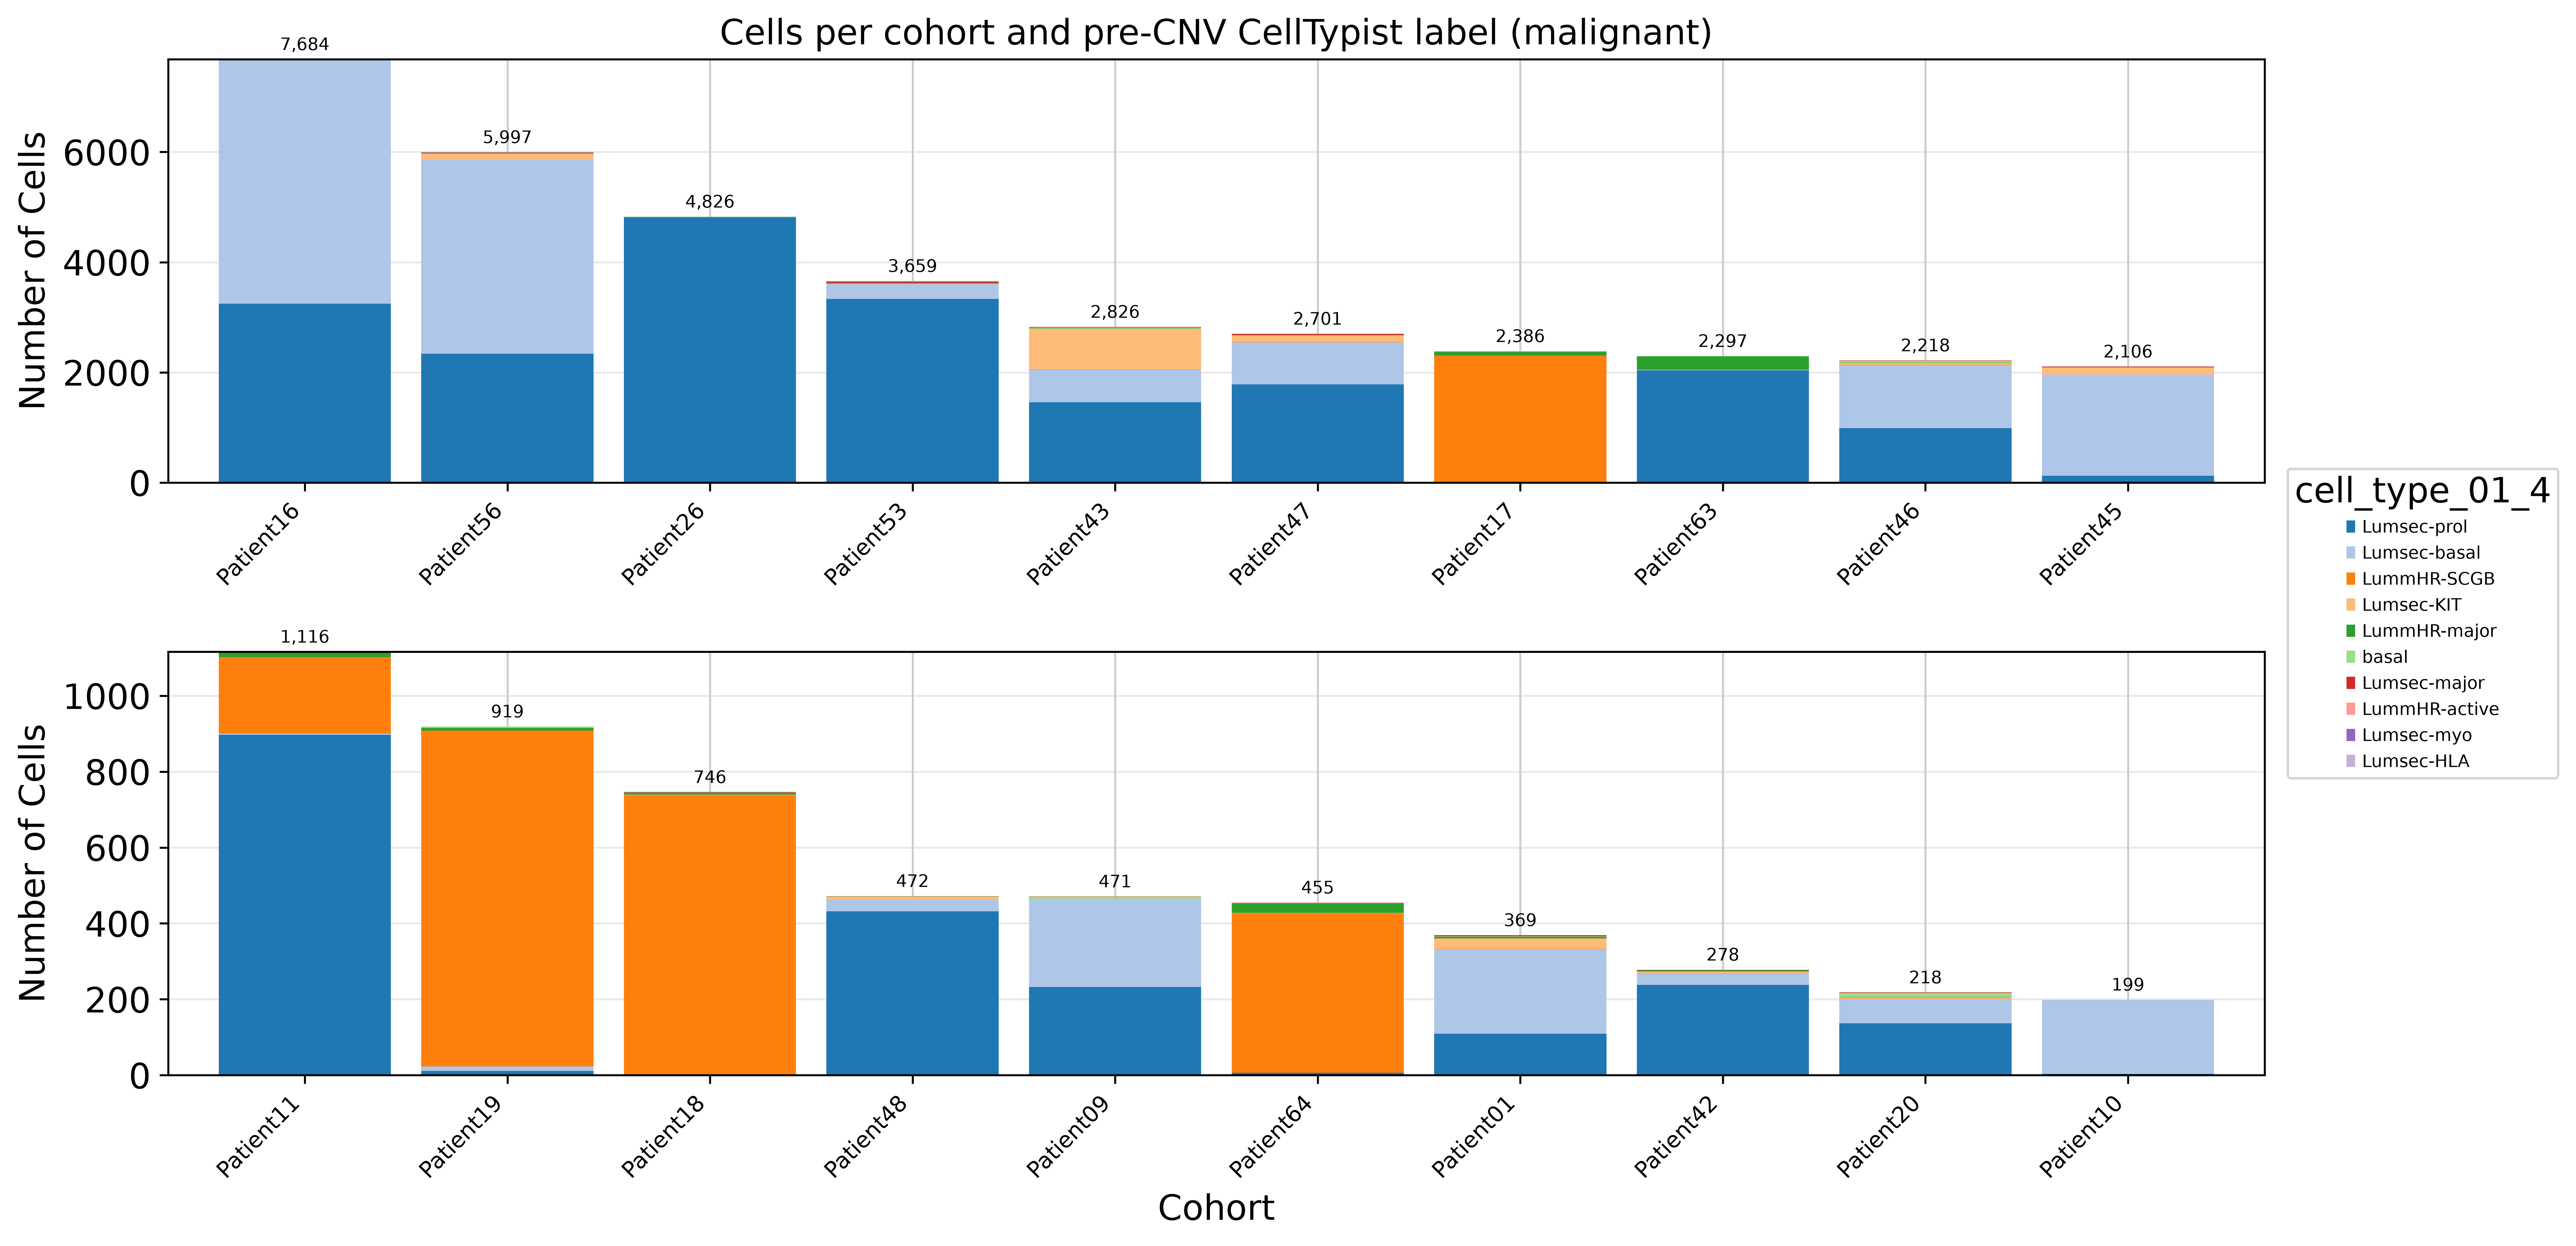

wrote /home/catt/QCB-thesis-final/03_drvi_tumoral_epi/tables/03_2_visualization/cells_per_cohort_and_label_tum.csv


cell_type_01_4,Lumsec-prol,Lumsec-basal,LummHR-SCGB,Lumsec-KIT,LummHR-major,basal,Lumsec-major,LummHR-active,Lumsec-myo,Lumsec-HLA
cohort,,,,,,,,,,
Patient16,3248,4418,1,7,0,7,3,0,0,0
Patient56,2339,3516,0,117,10,4,8,0,1,2
Patient26,4813,4,1,3,3,0,0,0,2,0
Patient53,3334,269,6,5,9,3,23,10,0,0
Patient43,1461,586,4,740,6,16,12,1,0,0
Patient47,1784,759,5,113,9,11,19,1,0,0
Patient17,14,1,2293,0,64,2,0,12,0,0
Patient63,2038,4,2,4,241,7,1,0,0,0
Patient46,991,1145,5,31,5,30,10,1,0,0


In [35]:
# Cells per cohort and label, every level kept (no "other").
cohort_label = pd.crosstab(adata.obs[BATCH_KEY], adata.obs[LABEL_FOR_PLOTS])
cohort_label = cohort_label.loc[cohort_label.sum(axis=1) > 0]
cohort_label = cohort_label.loc[cohort_label.sum(axis=1).sort_values(ascending=False).index]
cohort_label = cohort_label[[c for c in label_order if c in cohort_label.columns]]

N_PANELS = 2 if len(cohort_label) <= 20 else 3
panels = np.array_split(np.arange(len(cohort_label)), N_PANELS)

fig, axes = plt.subplots(N_PANELS, 1, figsize=(13, 3.6 * N_PANELS))
for ax, idx in zip(np.atleast_1d(axes), panels):
    block = cohort_label.iloc[idx]
    block.plot(kind='bar', stacked=True, ax=ax, width=0.85, legend=False,
               color=[LABEL_COLORS[c] for c in block.columns])
    for x, tot in enumerate(block.sum(axis=1)):
        ax.annotate(f'{tot:,}', (x, tot), ha='center', va='bottom', fontsize=7,
                    xytext=(0, 2), textcoords='offset points')
    ax.margins(y=0.12)
    ax.set_xlabel('')
    ax.set_ylabel('Number of Cells')
    ax.tick_params(axis='x', rotation=45, labelsize=9)
    ax.set_xticklabels(ax.get_xticklabels(), ha='right')
    ax.grid(axis='y', linestyle='-', alpha=0.4)
    ax.set_axisbelow(True)

np.atleast_1d(axes)[0].set_title(f'Cells per cohort and {LABEL_TITLE} ({SET_TITLE})')
np.atleast_1d(axes)[-1].set_xlabel('Cohort')
handles, legend_labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, title=LABEL_FOR_PLOTS, loc='center left',
           bbox_to_anchor=(0.99, 0.5), fontsize=7, ncol=1 + len(label_order) // 30)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'barplot_label_per_cohort_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()

# The same table on disk, with row and column totals.
cohort_label_csv = cohort_label.copy()
cohort_label_csv.loc['total'] = cohort_label_csv.sum()
cohort_label_csv['total'] = cohort_label_csv.sum(axis=1)
out = os.path.join(TABLE_DIR, f'cells_per_cohort_and_label_{SUFFIX}.csv')
cohort_label_csv.to_csv(out)
print('wrote', out)
cohort_label

<BarContainer object of 3 artists>

Text(0, 2, '11,656')

Text(0, 2, '25,315')

Text(0, 2, '4,972')

Text(0.5, 1.0, 'Number of malignant cells per treatment')

Text(0.5, 0, 'Treatment')

Text(0, 0.5, 'Number of Cells')

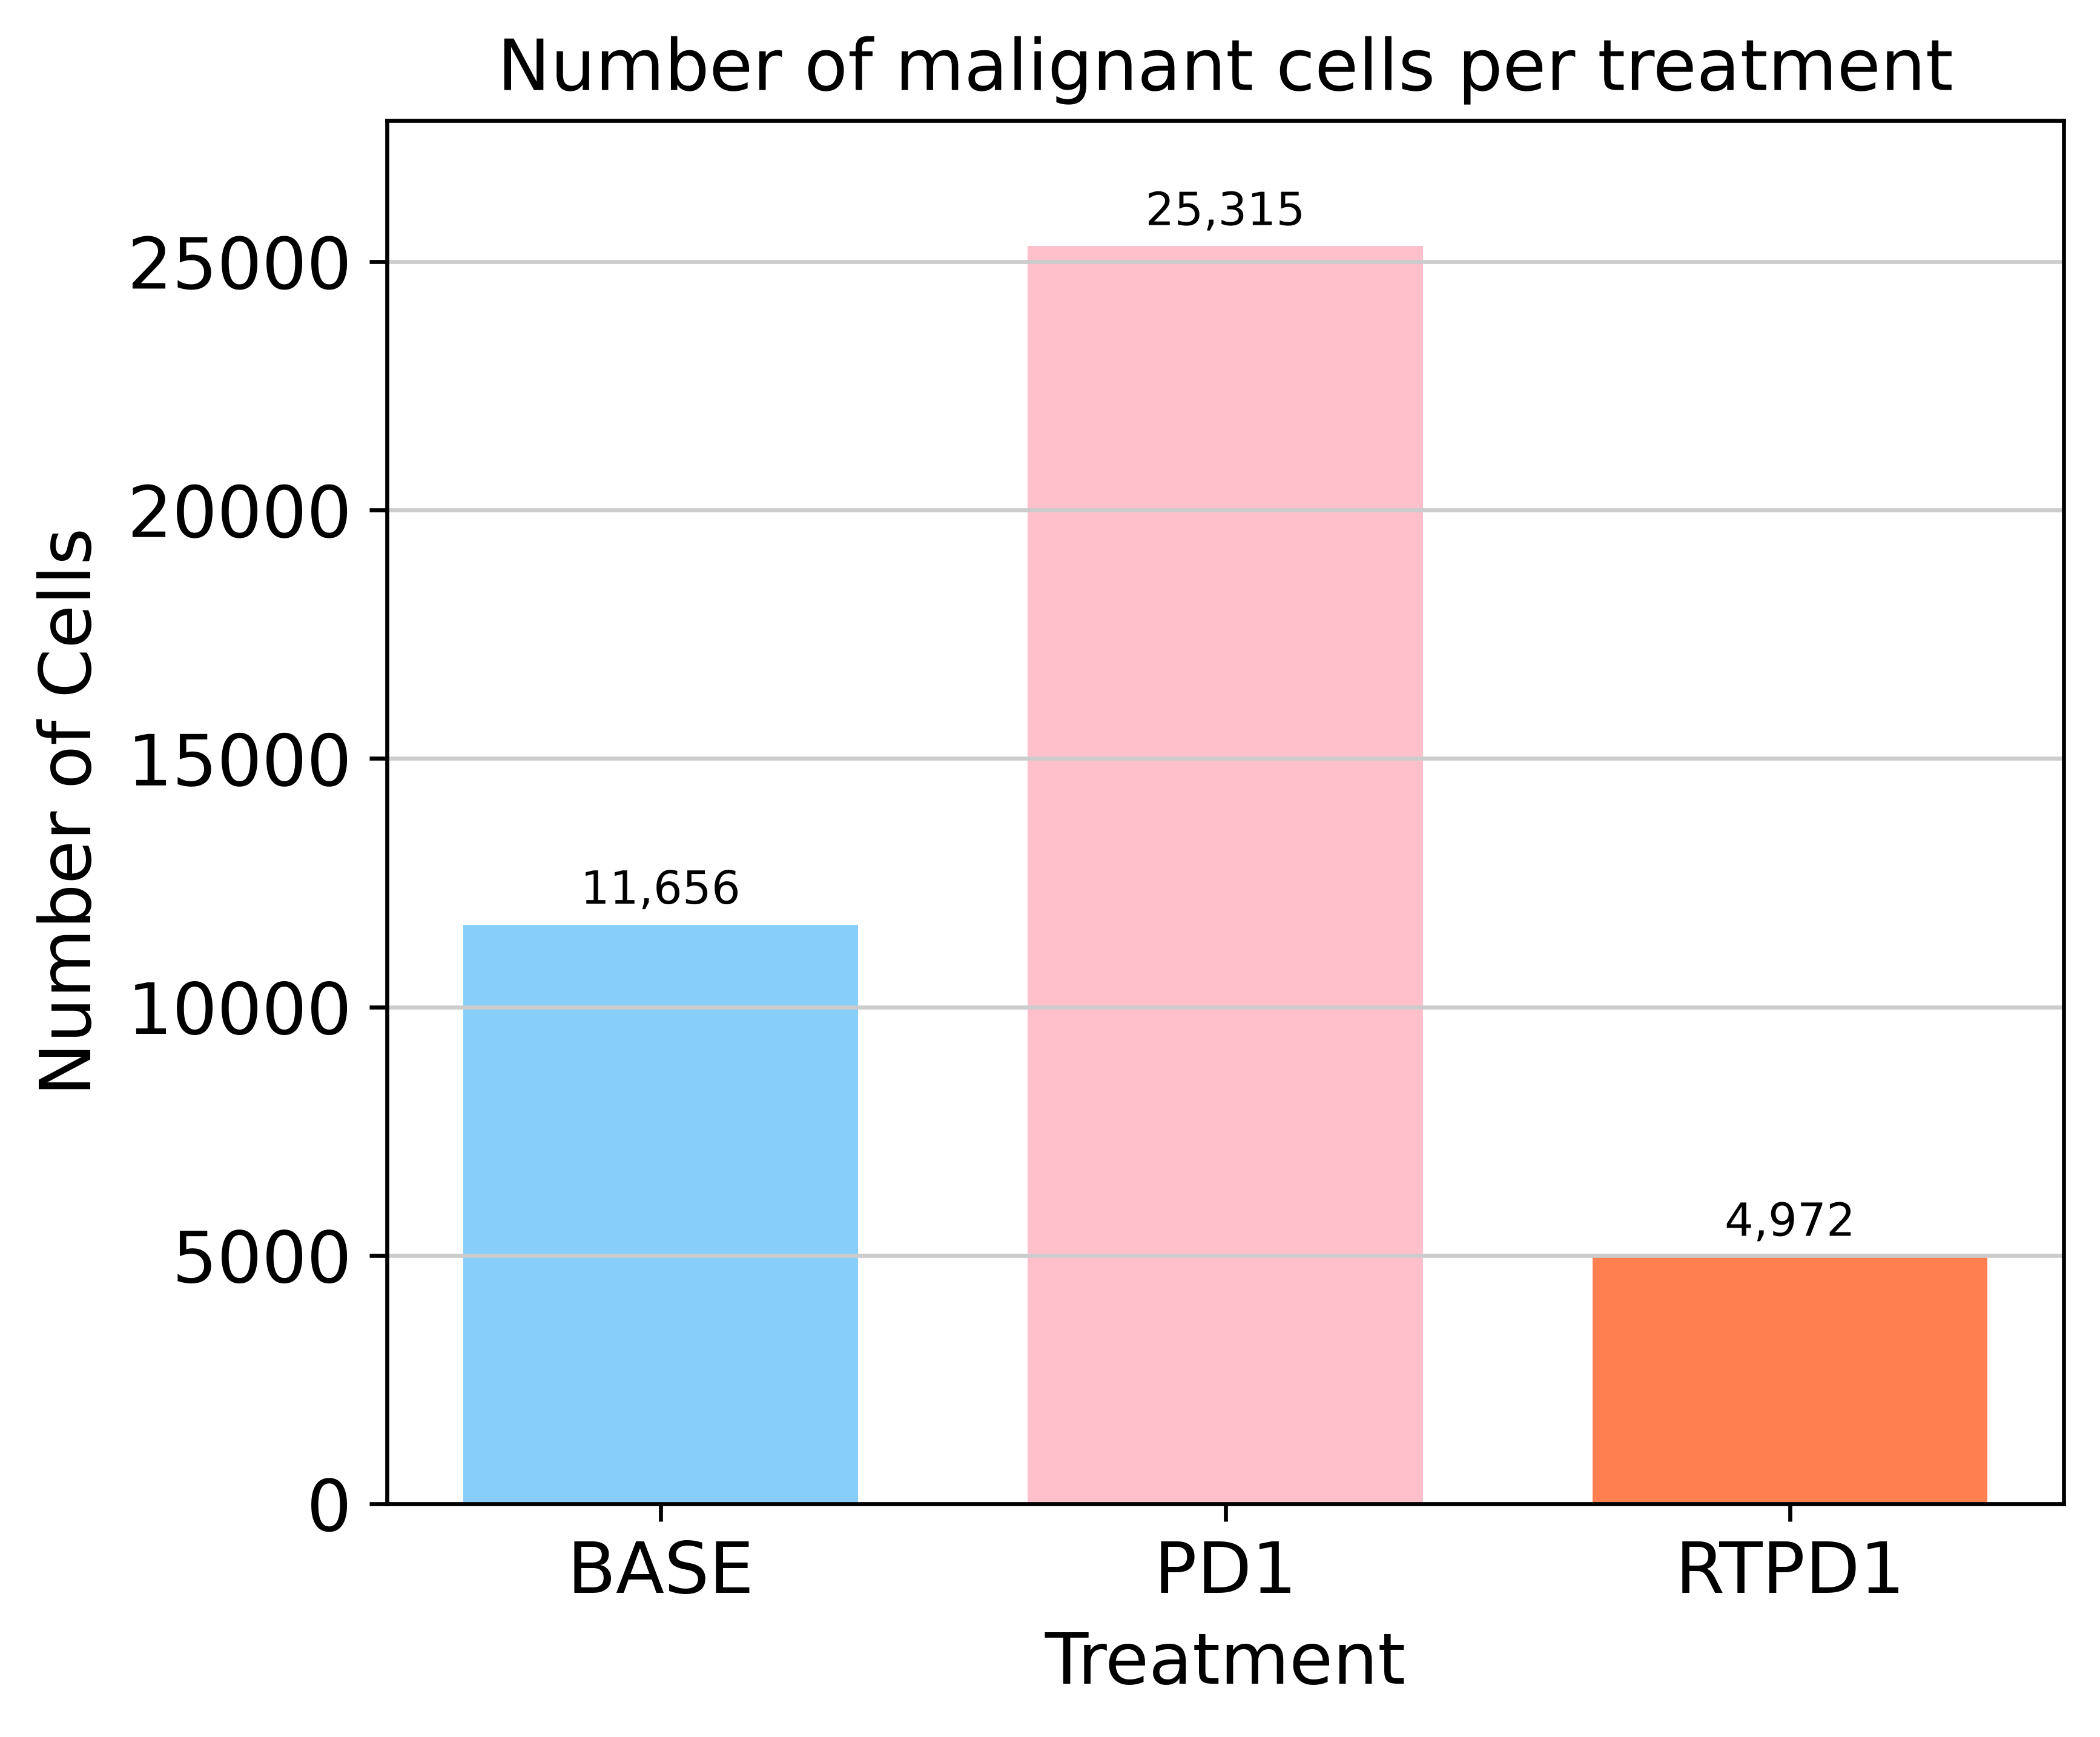

treatment
BASE     11656
PD1      25315
RTPD1     4972
Name: count, dtype: int64

In [36]:
# Cells per treatment.
cells_per_treatment = adata.obs['treatment'].value_counts().reindex(treatment_order)

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(treatment_order, cells_per_treatment.to_numpy(),
       color=[TREATMENT_COLORS[t] for t in treatment_order], width=0.7)
for x, n in enumerate(cells_per_treatment):
    ax.annotate(f'{n:,}', (x, n), ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')
ax.margins(y=0.1)
ax.set_title(f'Number of {SET_TITLE} cells per treatment')
ax.set_xlabel('Treatment')
ax.set_ylabel('Number of Cells')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'barplot_cells_per_treatment_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()
cells_per_treatment

Cells per patient and treatment. The heatmap counts the malignant cells of each biopsy, one row per patient and one column per timepoint (BASE, PD1, RTPD1); these are the samples compared in 03_9. 
Each column is shaded in the colour of its treatment in the barplots above, from pale to dark as the count grows on a shared log scale, and the patient total is in the row label. 
Biopsies without malignant cells are hatched in red and marked 0. The table below the figure lists the same counts.

In [37]:
# Cells per biopsy (cohort x treatment): the samples 03_9 compares.
cohort_x_treatment = pd.crosstab(adata.obs[BATCH_KEY], adata.obs['treatment'])
cohort_x_treatment = cohort_x_treatment.reindex(columns=list(C.REQUIRED_TREATMENTS), fill_value=0)
cohort_x_treatment = cohort_x_treatment.loc[cohort_x_treatment.sum(axis=1) > 0].sort_index()
ct_counts = cohort_x_treatment.to_numpy()
n_rows, n_cols = ct_counts.shape

cohort_x_treatment

treatment,BASE,PD1,RTPD1
cohort,,,
Patient01,253,0,116
Patient09,279,149,43
Patient10,63,136,0
Patient11,729,385,2
Patient16,583,7098,3
Patient17,170,218,1998
Patient18,164,570,12
Patient19,357,311,251
Patient20,78,127,13


<BarContainer object of 3 artists>

Text(0, 2, '13,631')

Text(0, 2, '11,453')

Text(0, 2, '16,859')

[Text(0, 0, 'NR\n(6 cohorts)'),
 Text(1, 0, 'R1\n(4 cohorts)'),
 Text(2, 0, 'R2\n(10 cohorts)')]

Text(0.5, 1.0, 'Number of malignant cells per response')

Text(0.5, 0, 'Response')

Text(0, 0.5, 'Number of Cells')

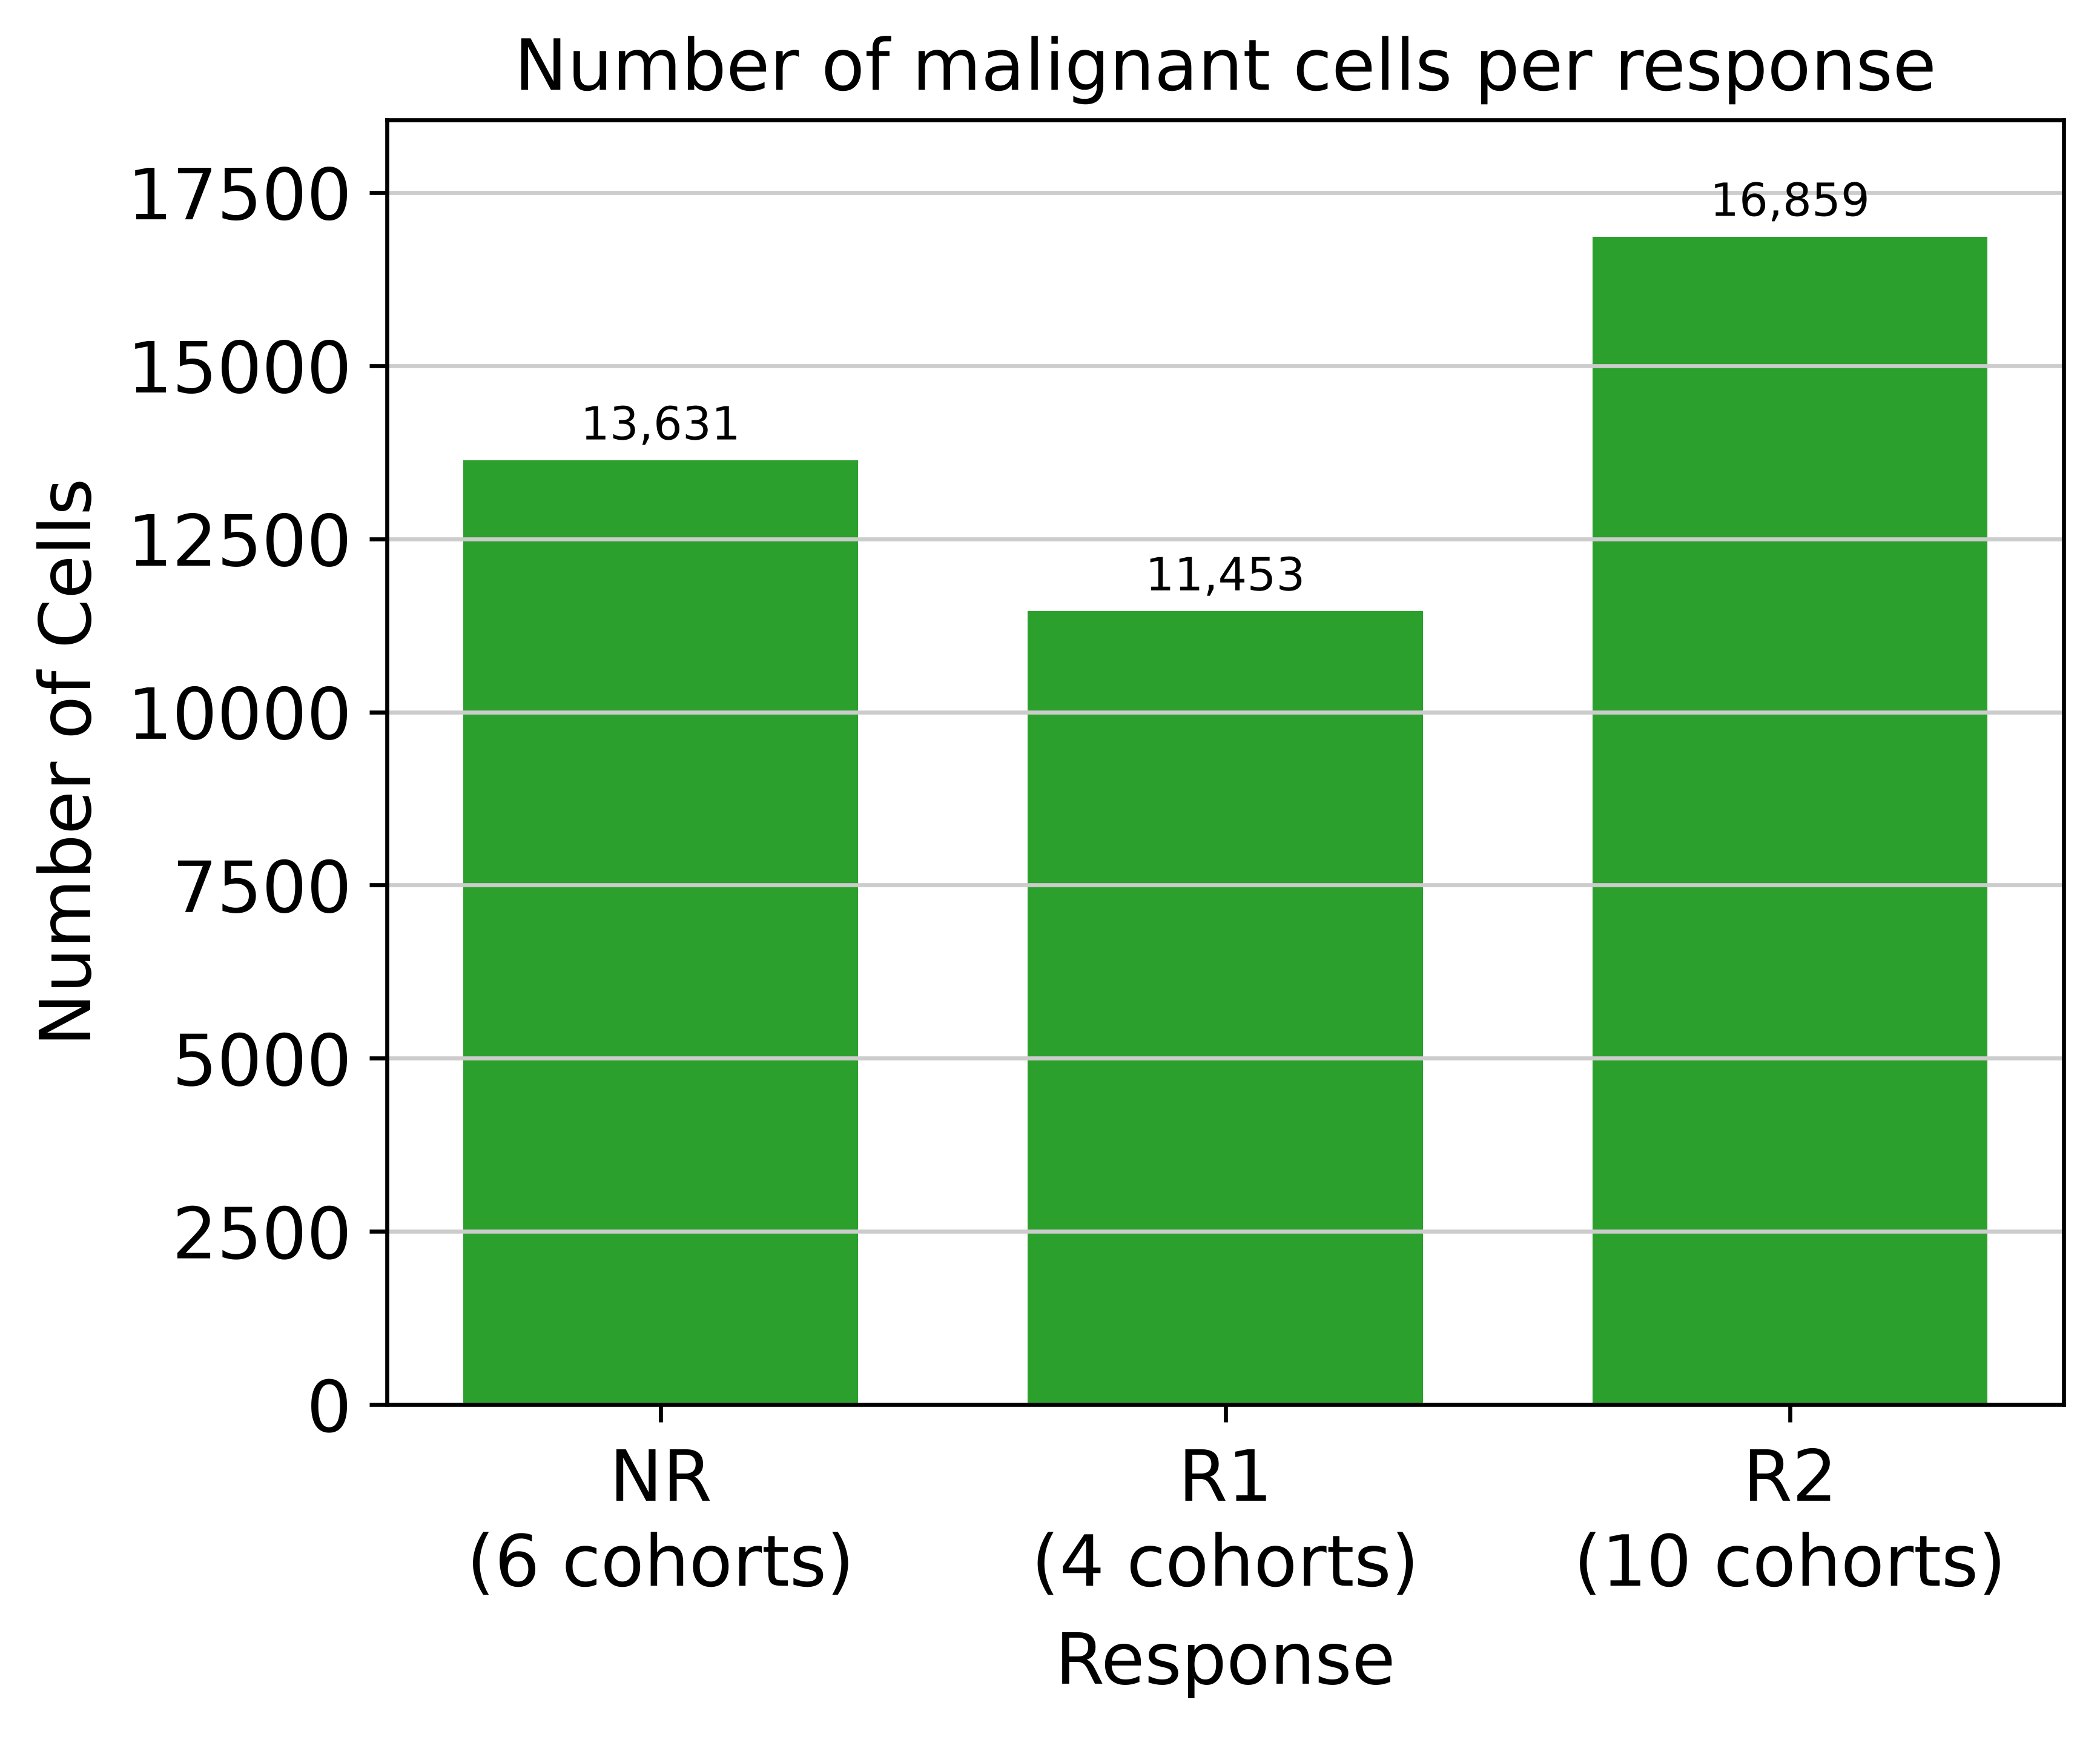

,cells,cohorts
response,,
NR,13631,6
R1,11453,4
R2,16859,10


In [38]:
# Cells per response group; the cohorts per group are in the tick labels.
RESPONSE_ORDER = ['NR', 'R1', 'R2']
response_order = [r for r in RESPONSE_ORDER if r in set(adata.obs['response'])]
cells_per_response = adata.obs['response'].value_counts().reindex(response_order)
cohorts_per_response = adata.obs.groupby('response', observed=True)[BATCH_KEY].nunique()

fig, ax = plt.subplots(figsize=(6, 5))
ax.bar(range(len(response_order)), cells_per_response.to_numpy(), color=QC_COLOR, width=0.7)
for x, n in enumerate(cells_per_response):
    ax.annotate(f'{n:,}', (x, n), ha='center', va='bottom', fontsize=9,
                xytext=(0, 2), textcoords='offset points')
ax.set_xticks(range(len(response_order)))
ax.set_xticklabels([f'{r}\n({cohorts_per_response[r]} cohorts)' for r in response_order])
ax.margins(y=0.1)
ax.set_title(f'Number of {SET_TITLE} cells per response')
ax.set_xlabel('Response')
ax.set_ylabel('Number of Cells')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'barplot_cells_per_response_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()
pd.DataFrame({'cells': cells_per_response, 'cohorts': cohorts_per_response.reindex(response_order)})

### Cell cycle phase distribution

Re-scored on this population by cell_cycle_score_tum.py. A high cycling fraction is expected on
malignant cells.

phase
G1     18840
S      12812
G2M    10291

cycling (S + G2M): 55.1%


<Axes: xlabel='cohort'>

Text(0.5, 1.0, 'Cell cycle phase distribution by cohort (malignant)')

Text(0.5, 0, 'Cohort')

Text(0, 0.5, 'Percentage of Cells')

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19]),
 [Text(0, 0, 'Patient16'),
  Text(1, 0, 'Patient56'),
  Text(2, 0, 'Patient26'),
  Text(3, 0, 'Patient53'),
  Text(4, 0, 'Patient43'),
  Text(5, 0, 'Patient47'),
  Text(6, 0, 'Patient17'),
  Text(7, 0, 'Patient63'),
  Text(8, 0, 'Patient46'),
  Text(9, 0, 'Patient45'),
  Text(10, 0, 'Patient11'),
  Text(11, 0, 'Patient19'),
  Text(12, 0, 'Patient18'),
  Text(13, 0, 'Patient48'),
  Text(14, 0, 'Patient09'),
  Text(15, 0, 'Patient64'),
  Text(16, 0, 'Patient01'),
  Text(17, 0, 'Patient42'),
  Text(18, 0, 'Patient20'),
  Text(19, 0, 'Patient10')])

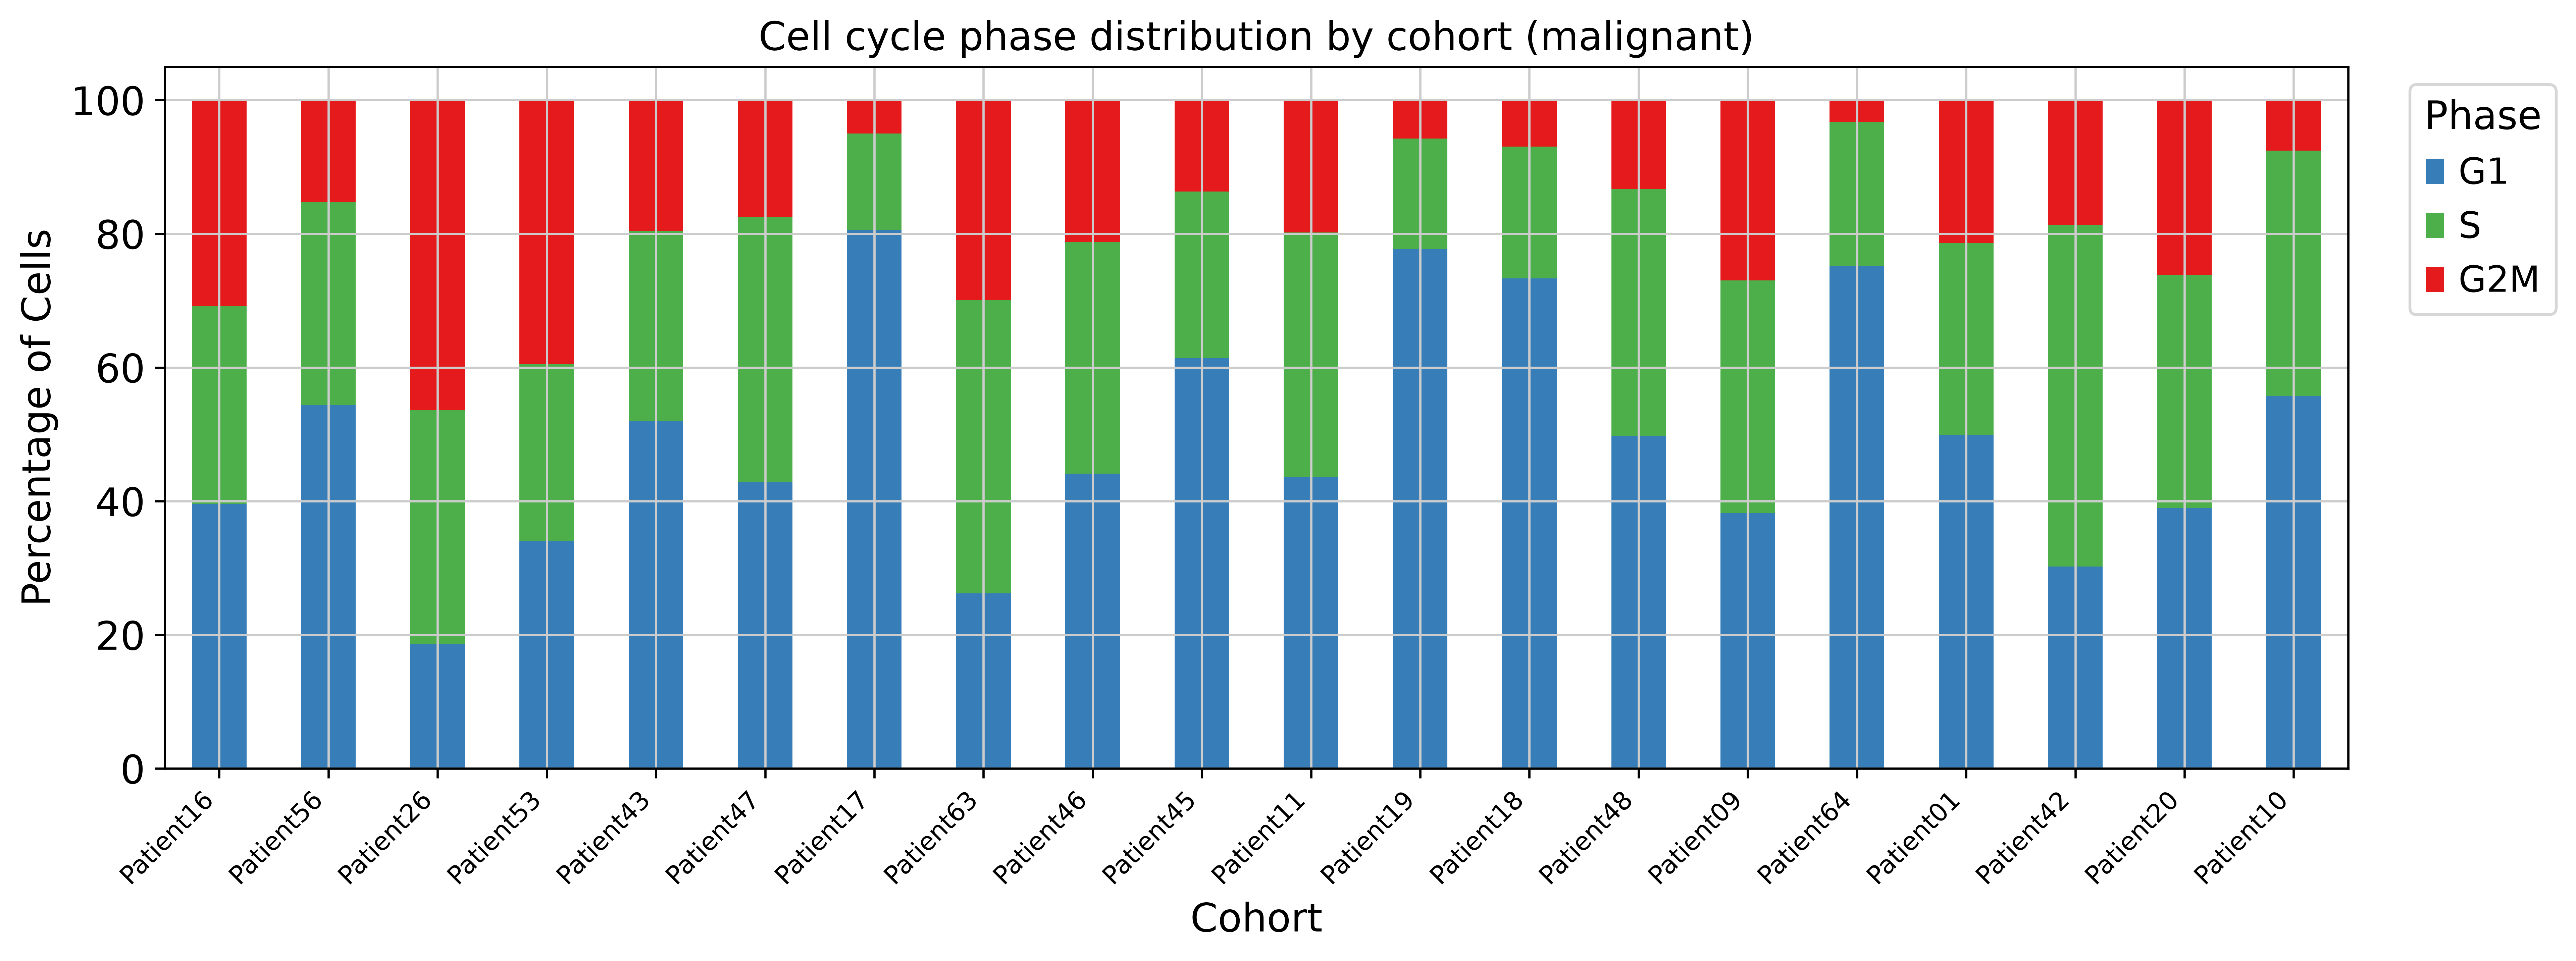

In [39]:
PHASE_ORDER = ['G1', 'S', 'G2M']
PHASE_COLORS = {'G1': '#377eb8', 'S': '#4daf4a', 'G2M': '#e41a1c'}

phase_counts = adata.obs['phase'].value_counts().reindex(PHASE_ORDER)
print(phase_counts.to_string())
print(f'\ncycling (S + G2M): {phase_counts[["S", "G2M"]].sum() / adata.n_obs:.1%}')

tmp = pd.crosstab(adata.obs[BATCH_KEY], adata.obs['phase'], normalize='index')
tmp = tmp.reindex(index=cells_per_cohort.index, columns=PHASE_ORDER) * 100
tmp.plot.bar(stacked=True, figsize=(13, 5), color=[PHASE_COLORS[p] for p in PHASE_ORDER])
plt.title(f'Cell cycle phase distribution by cohort ({SET_TITLE})')
plt.xlabel('Cohort')
plt.ylabel('Percentage of Cells')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.legend(title='Phase', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'barplot_cc_vs_cohort_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()

<Axes: xlabel='cell_type_01_4'>

Text(0.5, 1.0, 'Cell cycle phase distribution by pre-CNV CellTypist label (malignant)')

Text(0.5, 0, 'cell_type_01_4')

Text(0, 0.5, 'Percentage of Cells')

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, 'Lumsec-prol'),
  Text(1, 0, 'Lumsec-basal'),
  Text(2, 0, 'LummHR-SCGB'),
  Text(3, 0, 'Lumsec-KIT'),
  Text(4, 0, 'LummHR-major'),
  Text(5, 0, 'basal'),
  Text(6, 0, 'Lumsec-major'),
  Text(7, 0, 'LummHR-active'),
  Text(8, 0, 'Lumsec-myo'),
  Text(9, 0, 'Lumsec-HLA')])

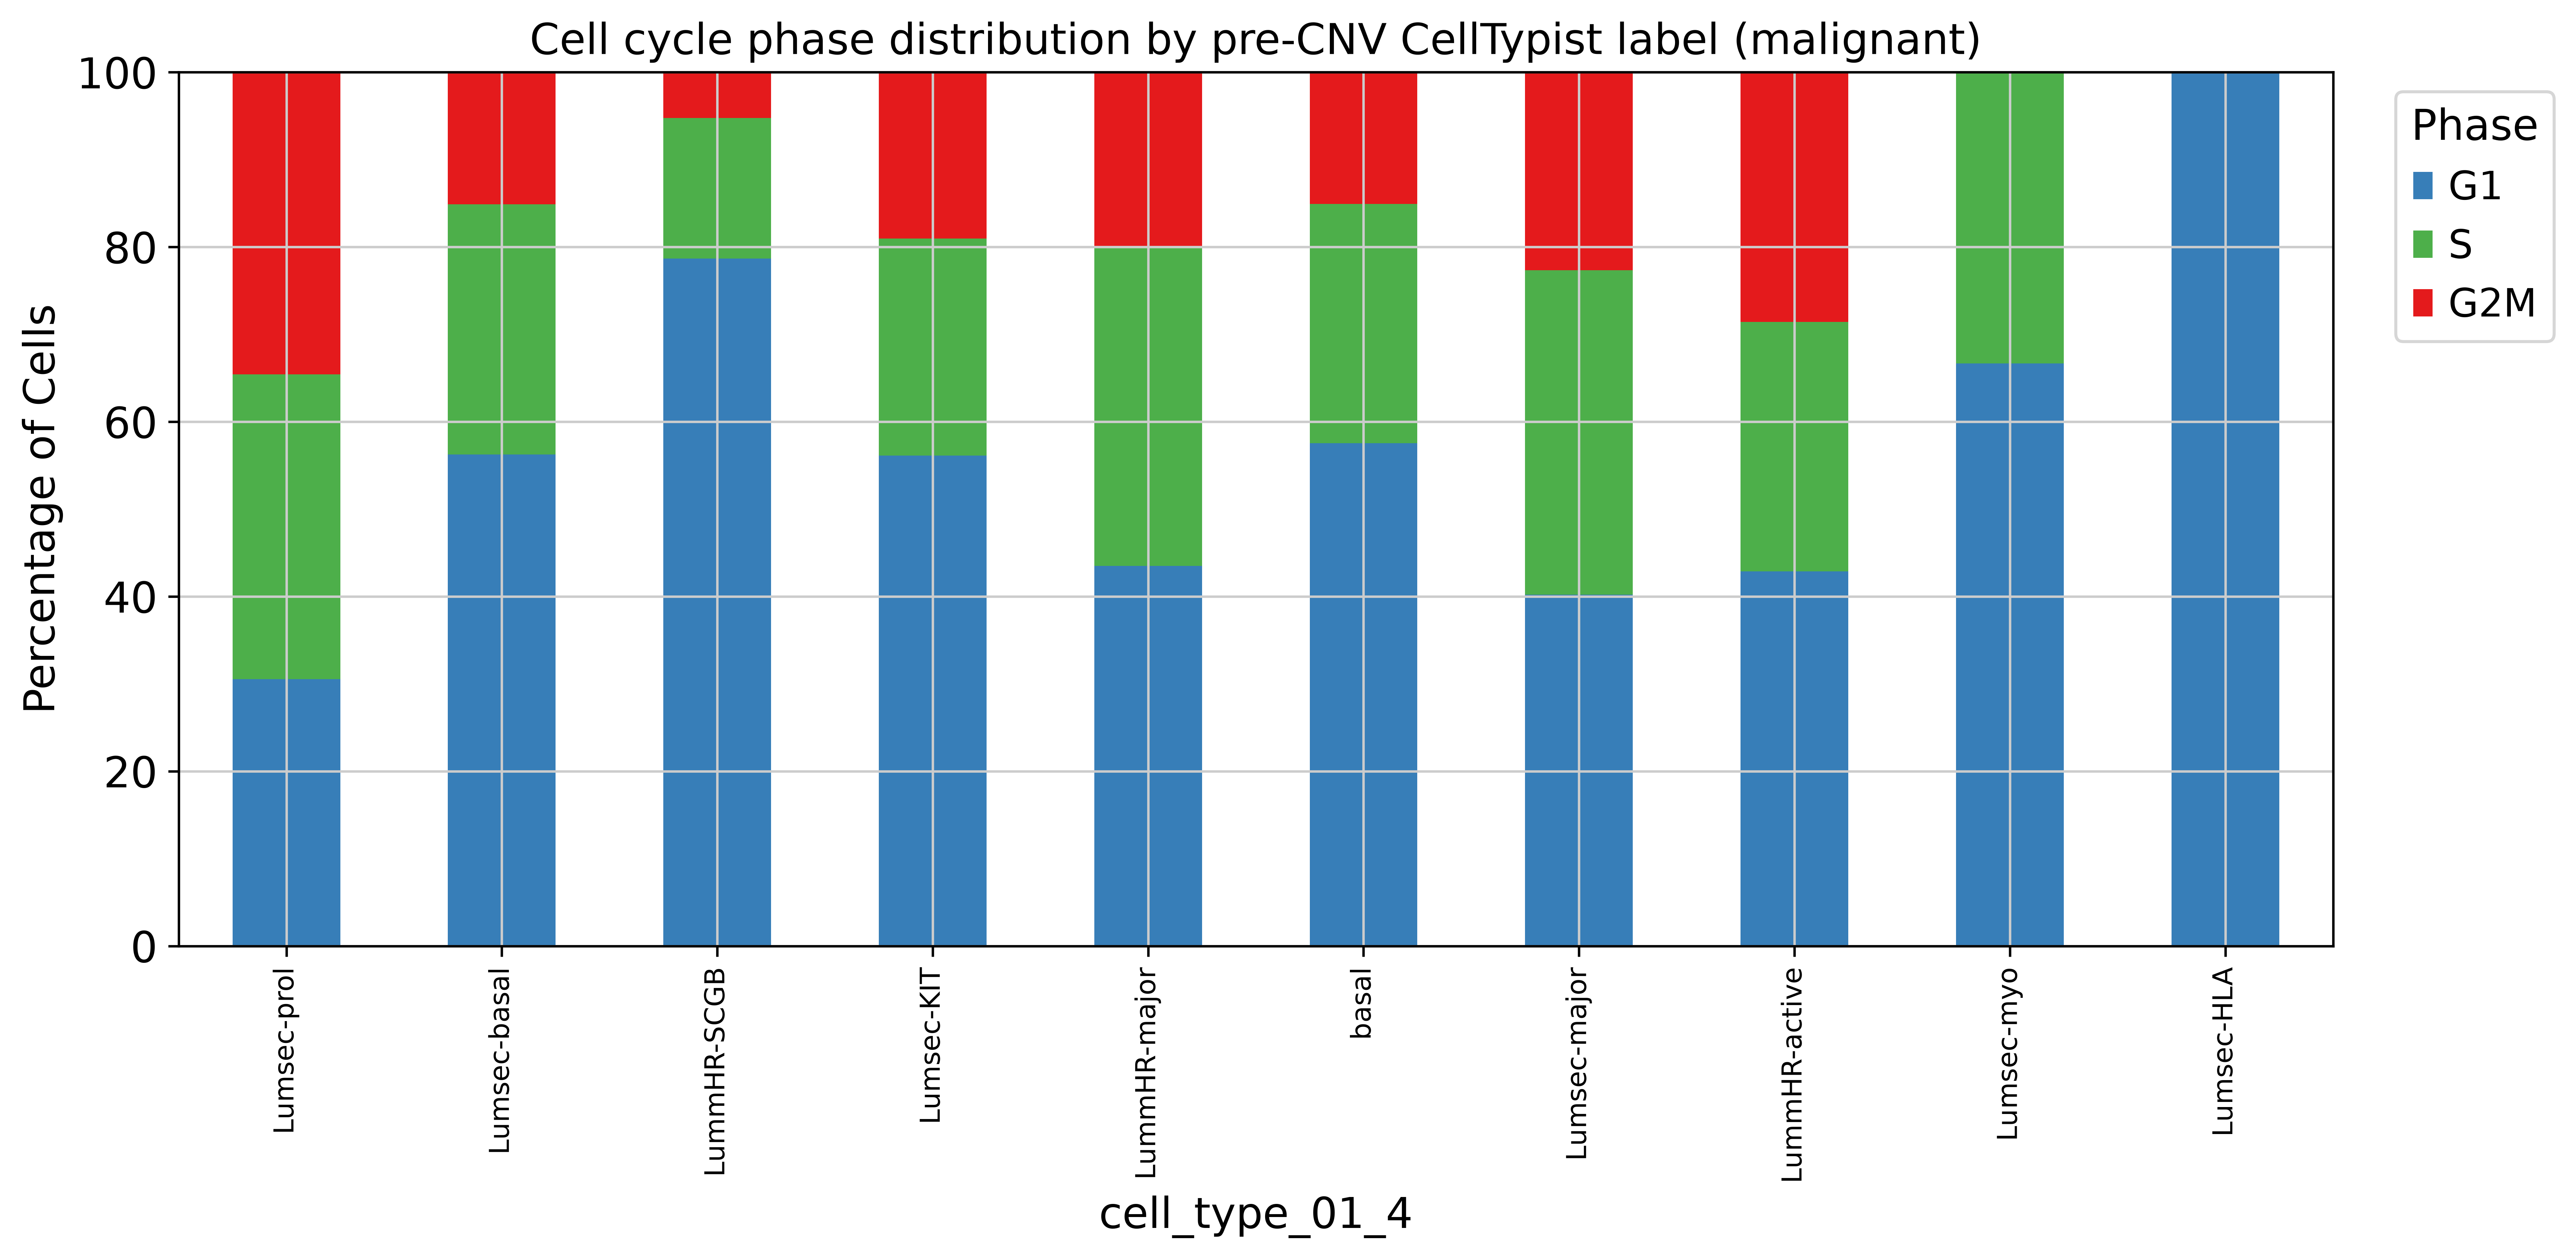

phase,G1,S,G2M
cell_type_01_4,,,
Lumsec-prol,30.5,34.9,34.6
Lumsec-basal,56.3,28.6,15.1
LummHR-SCGB,78.7,16.1,5.3
Lumsec-KIT,56.1,24.8,19.0
LummHR-major,43.5,36.6,19.9
basal,57.5,27.4,15.1
Lumsec-major,40.2,37.1,22.7
LummHR-active,42.9,28.6,28.6
Lumsec-myo,66.7,33.3,0.0


In [40]:
# By label: Lumsec-prol (proliferating in the atlas) should have the highest G2M share.
tmp = (pd.crosstab(adata.obs[LABEL_FOR_PLOTS], adata.obs['phase'], normalize='index')
       .reindex(index=label_order, columns=PHASE_ORDER) * 100)
tmp.plot.bar(stacked=True, figsize=(12, 6), color=[PHASE_COLORS[p] for p in PHASE_ORDER])
plt.title(f'Cell cycle phase distribution by {LABEL_TITLE} ({SET_TITLE})')
plt.xlabel(LABEL_FOR_PLOTS)
plt.ylabel('Percentage of Cells')
plt.xticks(rotation=90, fontsize=9)
plt.legend(title='Phase', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f'barplot_cc_vs_label_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()
tmp.round(1)

## Normalization: raw counts vs scran-normalized

.layers['counts'] = raw counts; .X = scran log-normalized, re-estimated on this subset.

In [41]:
# First cells of both matrices, on the most expressed genes so the view is not all zeros.
N_CELLS, N_GENES = 5, 8
top_genes = np.argsort(np.asarray(adata.layers['counts'].mean(axis=0)).ravel())[::-1][:N_GENES]

def head(mat):
    block = mat[:N_CELLS][:, top_genes]
    block = block.toarray() if hasattr(block, 'toarray') else np.asarray(block)
    return pd.DataFrame(block, index=adata.obs_names[:N_CELLS], columns=adata.var_names[top_genes])

print(".layers['counts'] (raw)")
head(adata.layers['counts'])
print('.X (scran log-normalized)')
head(adata.X).round(3)

.layers['counts'] (raw)


,MT-CO2,FTH1,GAPDH,FDCSP,MT-CO1,TMSB10,MGP,RPL41
P01_A_P_AAACCTGCAACTTGAC-1,280.0,65.0,91.0,0.0,274.0,152.0,234.0,57.0
P01_A_P_AAACCTGCATTATCTC-1,0.0,9.0,22.0,0.0,0.0,29.0,35.0,15.0
P01_A_P_AAACCTGGTCATGCAT-1,24.0,12.0,23.0,0.0,17.0,32.0,114.0,26.0
P01_A_P_AAACCTGTCTCTGCTG-1,314.0,143.0,104.0,0.0,384.0,152.0,2490.0,93.0
P01_A_P_AAACGGGCAGTCACTA-1,0.0,3.0,8.0,0.0,0.0,10.0,13.0,4.0


.X (scran log-normalized)


,MT-CO2,FTH1,GAPDH,FDCSP,MT-CO1,TMSB10,MGP,RPL41
P01_A_P_AAACCTGCAACTTGAC-1,4.730,3.298,3.624,0.0,4.708,4.126,4.552,3.172
P01_A_P_AAACCTGCATTATCTC-1,0.000,3.236,4.107,0.0,0.000,4.379,4.565,3.731
P01_A_P_AAACCTGGTCATGCAT-1,3.899,3.226,3.857,0.0,3.562,4.181,5.441,3.977
P01_A_P_AAACCTGTCTCTGCTG-1,4.987,4.208,3.896,0.0,5.187,4.269,7.051,3.786
P01_A_P_AAACGGGCAGTCACTA-1,0.000,2.561,3.493,0.0,0.000,3.710,3.967,2.830


### Size factors (scran, re-estimated on the subset)

A size factor at or below zero makes logNormCounts undefined, a known scran failure on small,
homogeneous populations: checked here.

size_factors: min=0.0273, max=11.7904, n(<=0)=0


/tmp/ipykernel_89279/2423509632.py:6: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.scatter(adata, 'size_factors', 'total_counts', color=LABEL_FOR_PLOTS,


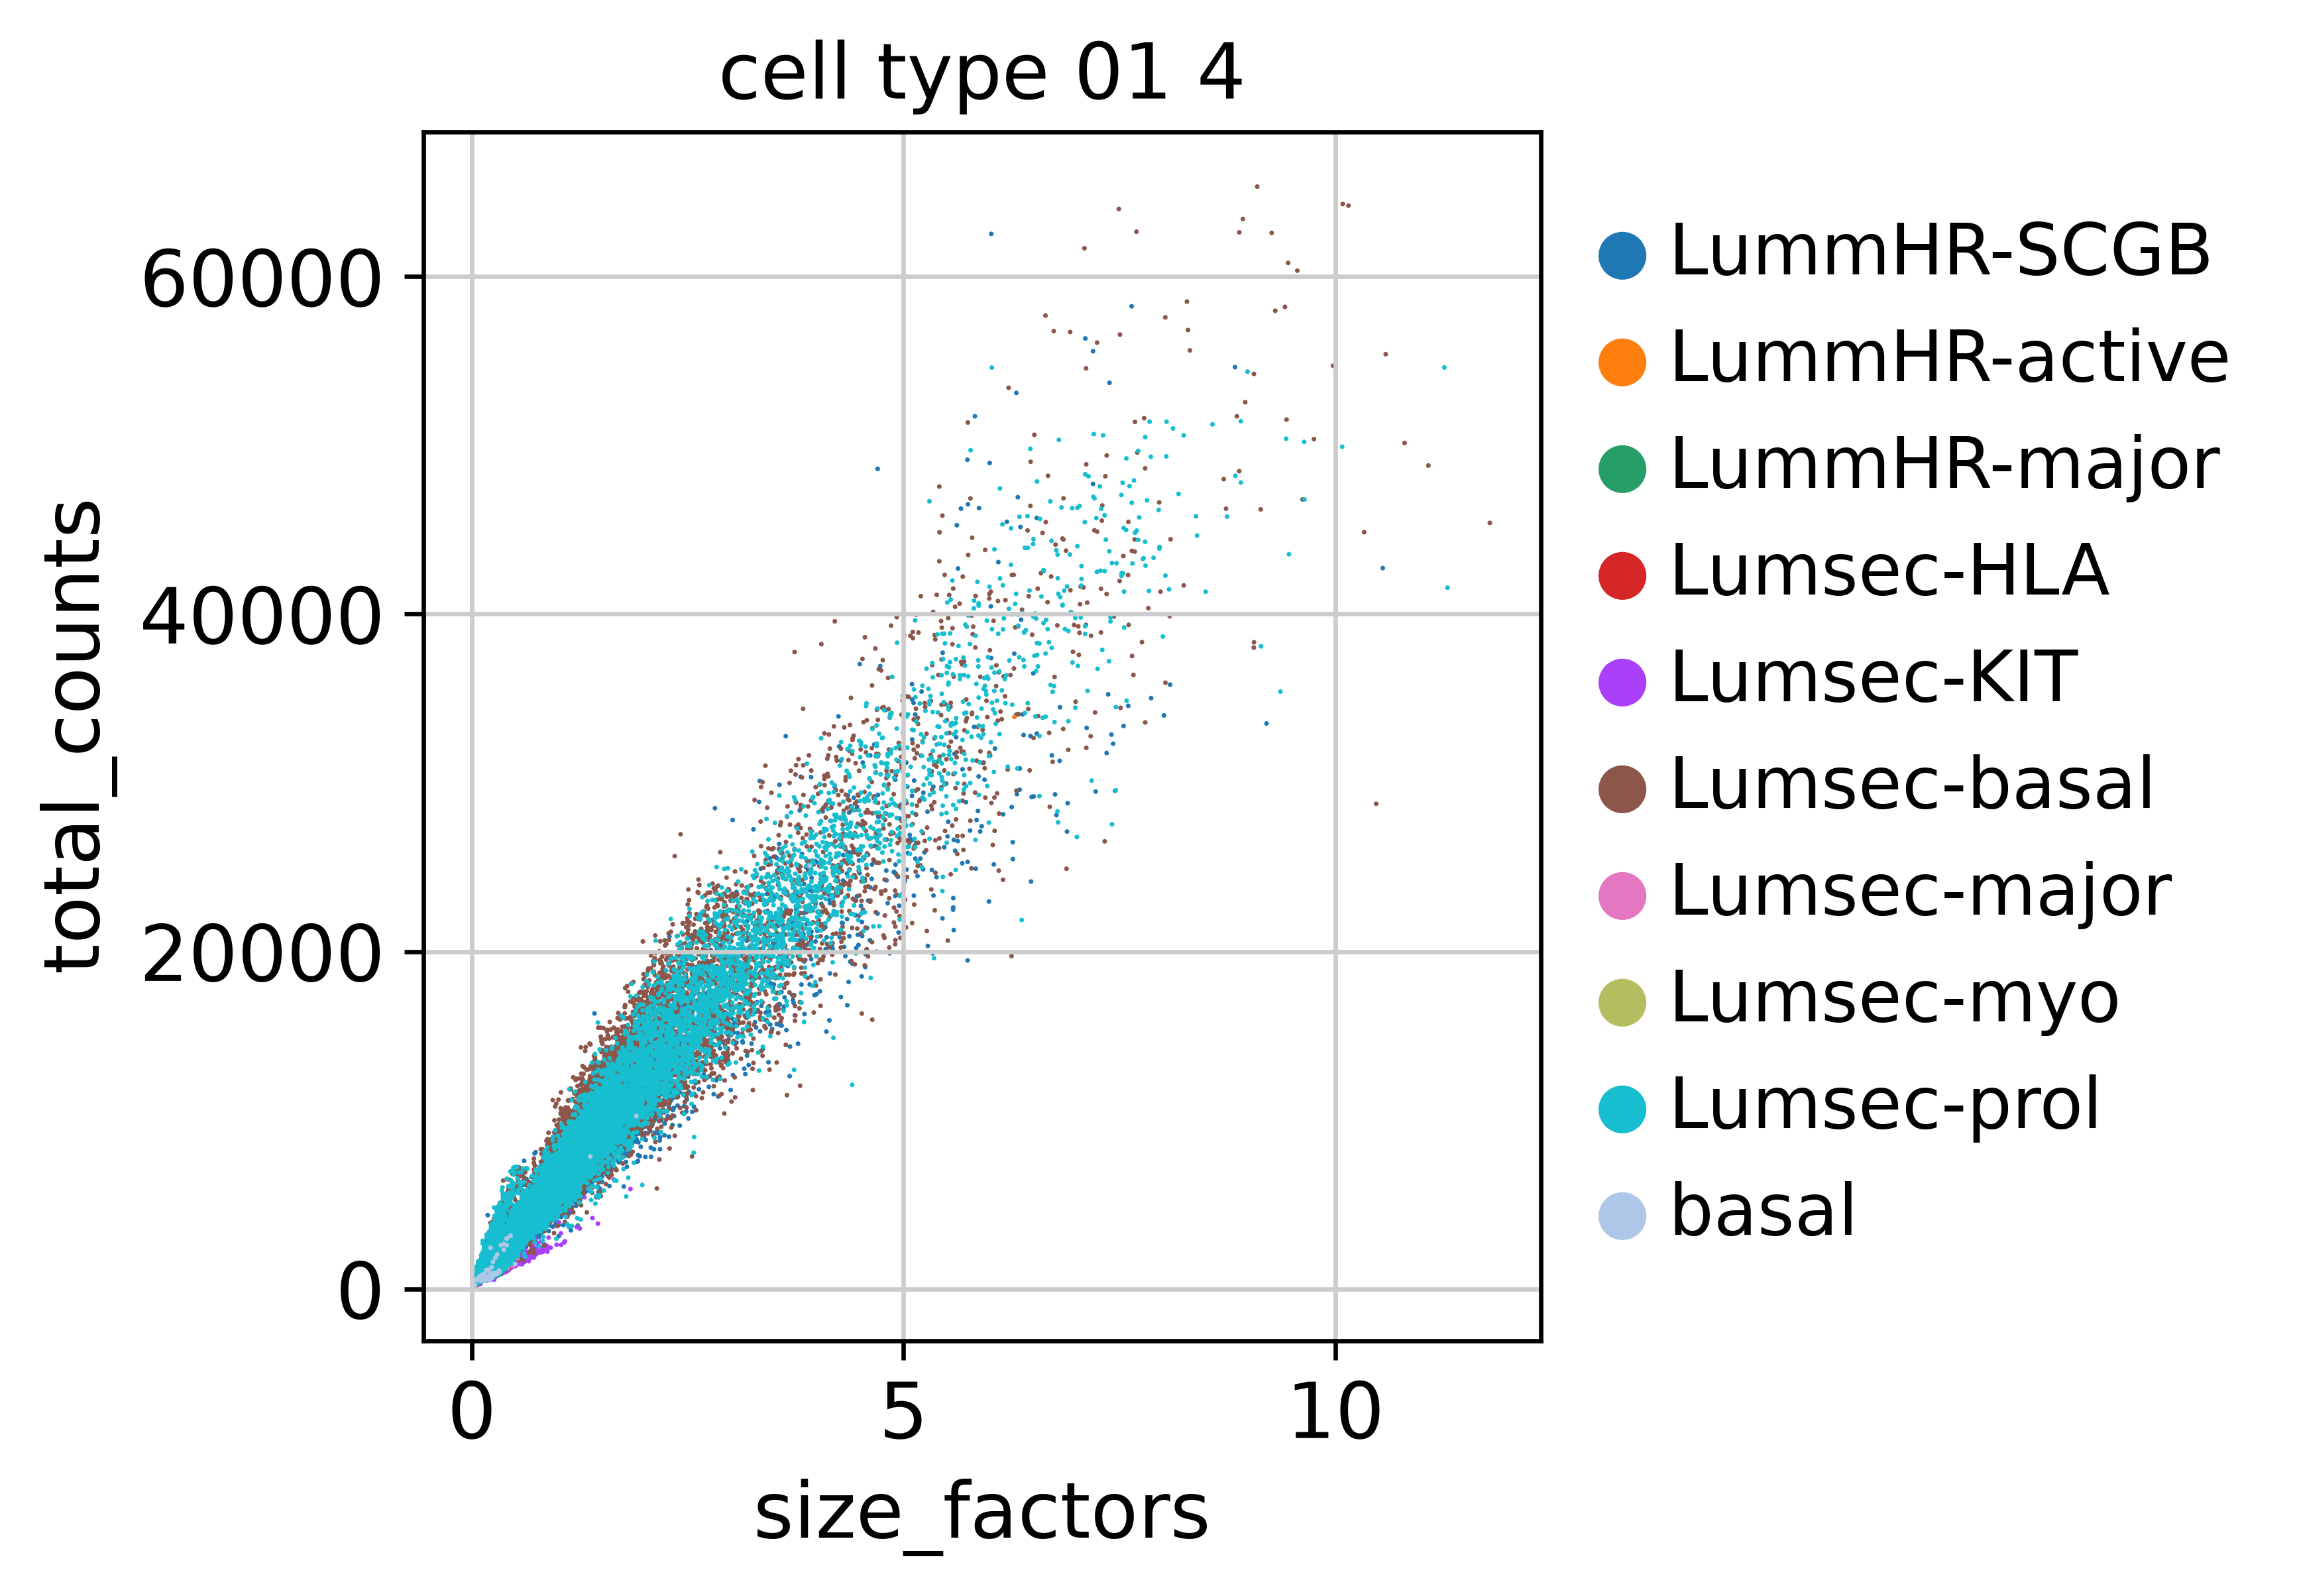

/tmp/ipykernel_89279/2423509632.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.scatter(adata, 'size_factors', 'n_genes_by_counts', color=LABEL_FOR_PLOTS,


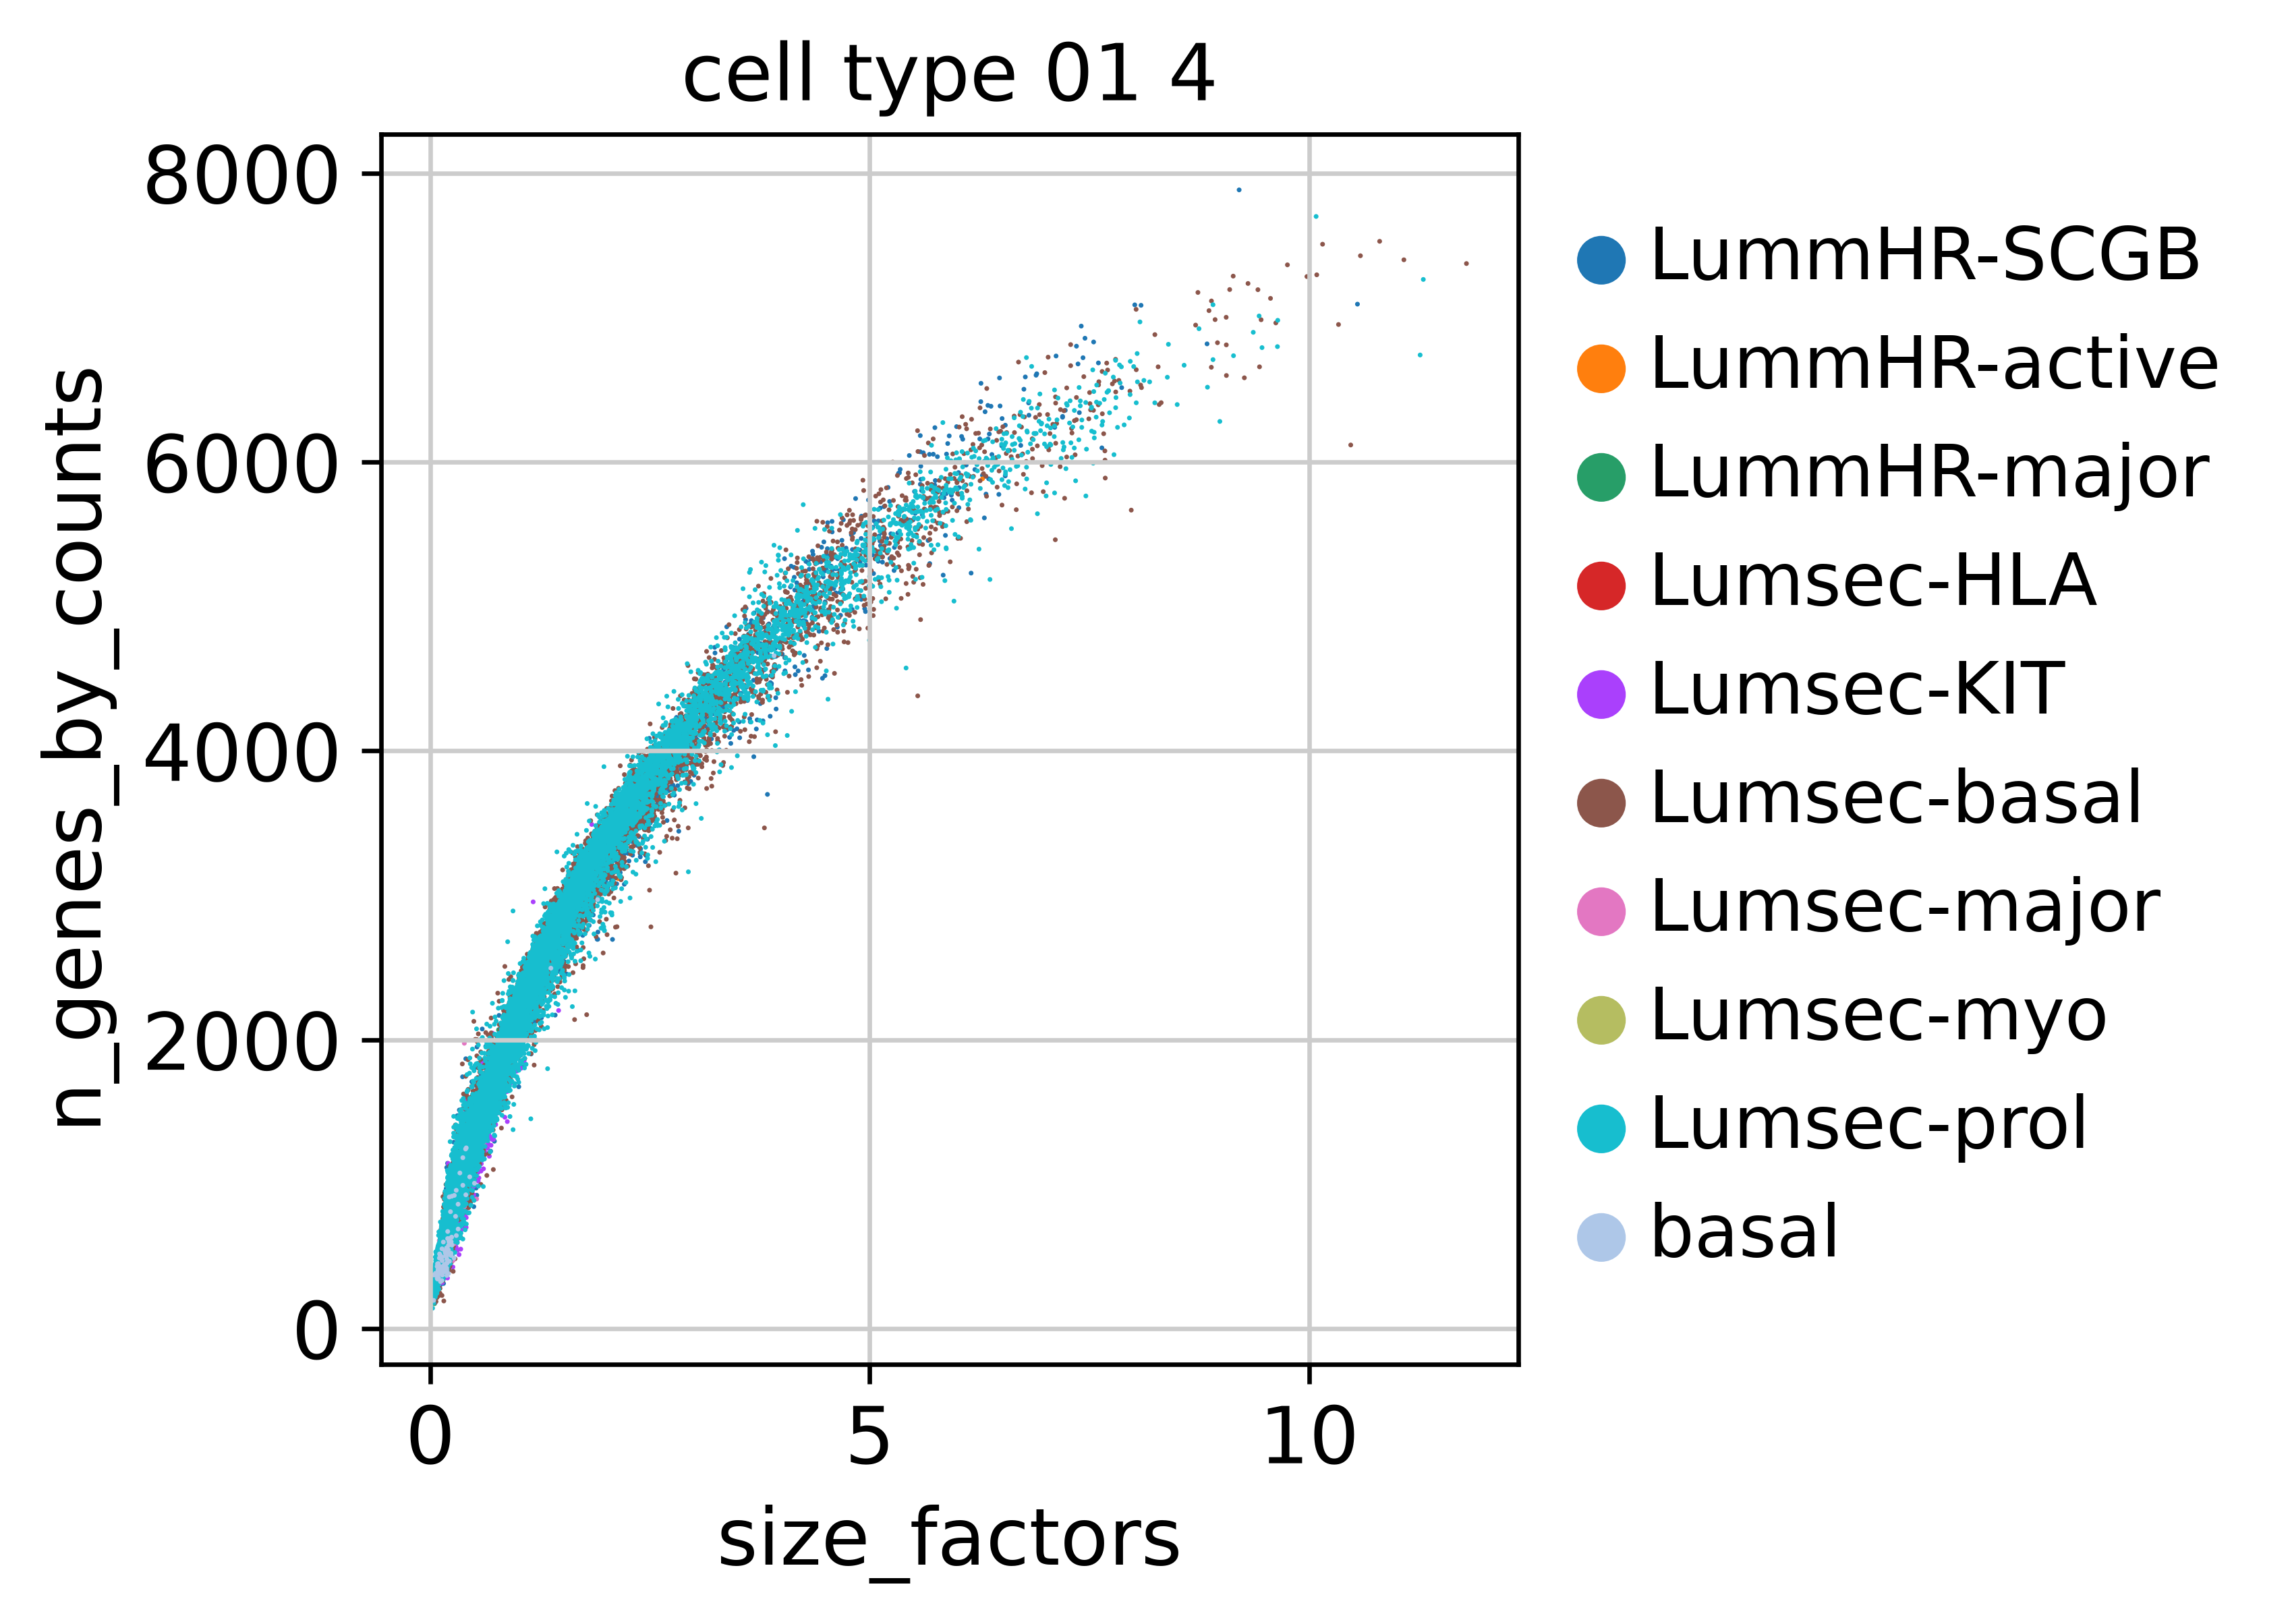

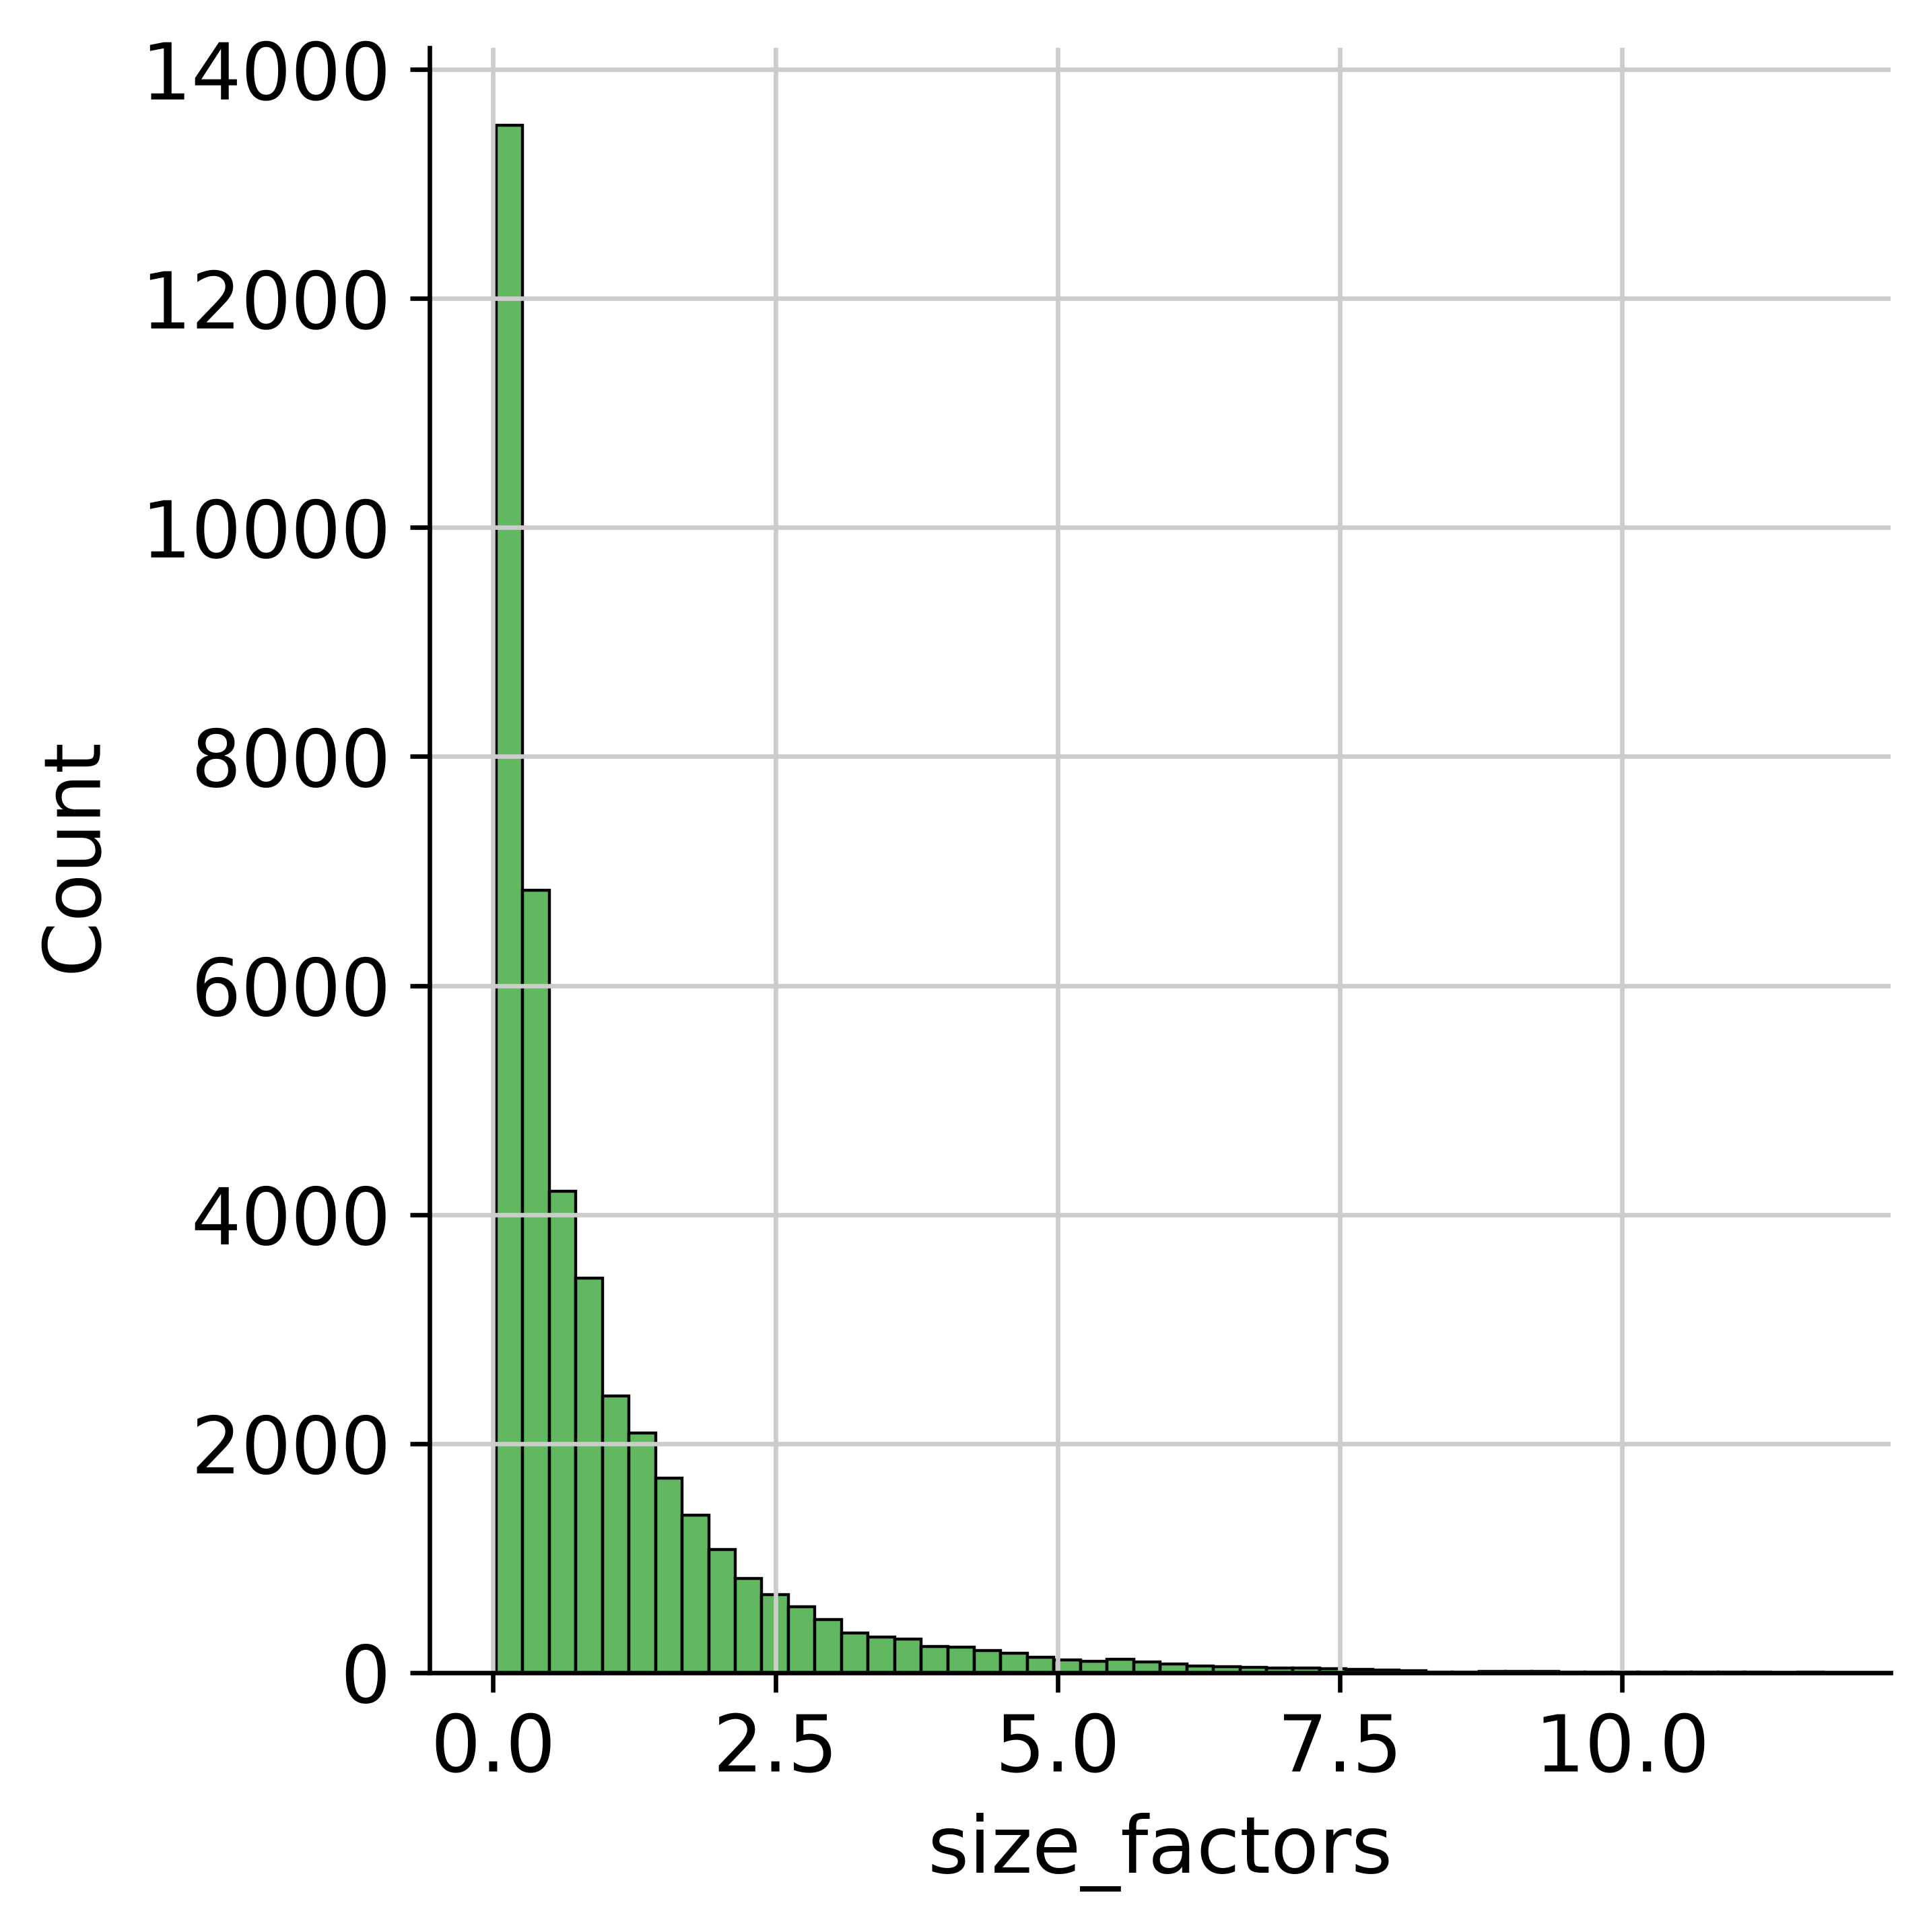

count    41943.000000
mean         1.000000
std          1.234573
min          0.027293
25%          0.200079
50%          0.527425
75%          1.314619
max         11.790404
Name: size_factors, dtype: float64

In [42]:
n_bad = int((adata.obs['size_factors'] <= 0).sum())
print(f'size_factors: min={adata.obs["size_factors"].min():.4f}, '
      f'max={adata.obs["size_factors"].max():.4f}, n(<=0)={n_bad}')
assert n_bad == 0, 'a non-positive size factor survived: the normalization is not usable'

sc.pl.scatter(adata, 'size_factors', 'total_counts', color=LABEL_FOR_PLOTS,
              save=f'_size_factors_vs_total_counts_by_label_{SUFFIX}_unintegrated.png')
sc.pl.scatter(adata, 'size_factors', 'n_genes_by_counts', color=LABEL_FOR_PLOTS,
              save=f'_size_factors_vs_n_genes_by_counts_by_label_{SUFFIX}_unintegrated.png')

sns.displot(adata.obs['size_factors'], bins=50, kde=False, color=QC_COLOR)
plt.savefig(os.path.join(FIG_DIR, f'displot_size_factors_{SUFFIX}_unintegrated.png'),
            dpi=300, bbox_inches='tight')
plt.show()

adata.obs['size_factors'].describe()

## Feature selection

The 2,000 batch-aware HVGs of reduce_data_tum.py (MT- genes replaced) and their overlap with the 01_5 selection on the full object.

In [43]:
hvg_genes = adata.var_names[adata.var['highly_variable']]
print(f'HVGs: {len(hvg_genes):,}')

HVG_REFS = [
    ('shiao_hvg_2k_unintegrated_list.csv', '01_5 full-object'),
]

for rel, label in HVG_REFS:
    p = os.path.join(os.environ['DATA_DIR'], rel)
    if not os.path.exists(p):
        print(f'{label:20s}: list not found at {p}, skipped')
        continue
    other = set(pd.read_csv(p, header=None)[0].astype(str))
    shared = set(hvg_genes) & other
    print(f'{label:20s}: {len(shared):,}/{len(hvg_genes):,} ({100 * len(shared) / len(hvg_genes):.1f}%)')

# The genes selected here and not on the full object.
all_earlier = set()
for rel, _ in HVG_REFS:
    p = os.path.join(os.environ['DATA_DIR'], rel)
    if os.path.exists(p):
        all_earlier |= set(pd.read_csv(p, header=None)[0].astype(str))
only_here = sorted(set(hvg_genes) - all_earlier)
print(f'\nnew in this selection (not in the 01_5 list): {len(only_here):,}')
print(f'first 30: {only_here[:30]}')

HVGs: 2,000
01_5 full-object    : 1,031/2,000 (51.5%)

new in this selection (not in the 01_5 list): 969
first 30: ['A1BG', 'AARS', 'ABCA12', 'ABCC9', 'ABCD2', 'ABI3', 'AC004241.1', 'AC004771.3', 'AC004771.4', 'AC005944.1', 'AC007566.1', 'AC007906.2', 'AC008105.1', 'AC008736.1', 'AC008906.2', 'AC009113.1', 'AC010280.1', 'AC010642.2', 'AC011450.1', 'AC011479.1', 'AC011603.2', 'AC015912.3', 'AC016738.1', 'AC016831.1', 'AC017083.2', 'AC022075.1', 'AC022509.1', 'AC022784.3', 'AC026367.3', 'AC027796.4']


## UMAPs

On the 50 PCs of the HVGs, without batch correction: the cohort structure is what DRVI has to
absorb in 03_3. It is stronger than in earlier phases, as every tumor is its own clone, so patient
and biology are partly confounded.

In [ ]:
UMAP_KEYS = {
    'label': LABEL_FOR_PLOTS,
    'cohort': BATCH_KEY,
    'treatment': 'treatment',
    'response': 'response',
    'phase': 'phase',
    'cnv_corr': 'cnv_corr',
    'n_genes_by_counts': 'n_genes_by_counts',
    'total_counts': 'total_counts',
    'mito': 'pct_counts_mt',
    'ribo': 'pct_counts_ribo',
    'size_factors': 'size_factors',
}
if HAS_STATUS:
    UMAP_KEYS['cnv_status'] = STATUS_KEY

UMAP_SEED = 0

# Random draw order, so the last cohort is not drawn on top; obs + UMAP only, no expression matrix.
_order = np.random.default_rng(UMAP_SEED).permutation(adata.n_obs)
adata_plot = ad.AnnData(
    obs=adata.obs.iloc[_order].copy(),
    obsm={'X_umap': adata.obsm['X_umap'][_order]},
    uns={k: v for k, v in adata.uns.items() if k.endswith('_colors')},
)

for name, col in UMAP_KEYS.items():
    sc.pl.umap(adata_plot, color=col, save=f'_{name}_{SUFFIX}_unintegrated.png')

In [ ]:
# Metadata panels in one grid for the thesis figure, same layout as 01_6.
UMAP_COMBINED_KEYS = [LABEL_FOR_PLOTS, BATCH_KEY, 'treatment', 'response', 'phase']
if HAS_STATUS:
    UMAP_COMBINED_KEYS.insert(1, STATUS_KEY)

with plt.rc_context({'figure.figsize': (7, 7)}):
    sc.pl.umap(adata_plot, color=UMAP_COMBINED_KEYS, ncols=2, wspace=0.8, hspace=0.25,
               save=f'_combined_{SUFFIX}_unintegrated.png')

## Next

shiao_tum_hvg_2k_nomt.h5ad (2,000 HVGs without the MT- genes, raw counts in the counts layer) is the input of 03_3, where DRVI is trained with cohort as batch key.